#I. Import dữ liệu

In [ ]:
!pip -q install gdown pandas

from pathlib import Path
import pandas as pd
import gdown
import re

# Dán link folder Google Drive public vào đây
folder_url = "https://drive.google.com/drive/folders/1WMeIajroEakGEvWeIl75HM6DxTc1GJDv?usp=drive_link"

# Thư mục tải về trên Colab
download_dir = Path("/content/my_csvs")
download_dir.mkdir(parents=True, exist_ok=True)

# Tải toàn bộ file trong folder, giữ nguyên tên gốc
gdown.download_folder(url=folder_url, output=str(download_dir), quiet=False, remaining_ok=True)

# Tạo biến dạng df_<tên_file>
created_dfs = []

for csv_file in download_dir.rglob("*.csv"):
    # Lấy tên file bỏ .csv
    file_name = csv_file.stem

    # Chuẩn hóa tên biến: thay ký tự lạ thành _
    safe_name = re.sub(r"\W+", "_", file_name.lower())
    var_name = f"df_{safe_name}"

    # Đọc file và gán thành biến
    globals()[var_name] = pd.read_csv(csv_file)
    created_dfs.append(var_name)

print("Created DataFrames:", created_dfs)

Retrieving folder contents


Processing file 1qP7QFNUfzHmlrF0YVwpGvhM-I7yvC2u0 customers.csv
Processing file 1CzMGx8Zr09ywZwOlOTWOhmcj0tyEUgjE geography.csv
Processing file 1ZdumFIvJDVnWwfZGtr-_bE7CsrxY-ez5 inventory.csv
Processing file 1bVCL6Qiml18OVxxCvJZ01D6agLcpYsls order_items.csv
Processing file 1nk6Eq8CisZKOggbSX5uMa_AQJdDw4fil orders.csv
Processing file 1RVdbvawVjCpMmYWywb4843kJIl5TppRS payments.csv
Processing file 1y5ztQaSdBUiR2CDAN4n4ZHtPN9WGOdND products.csv
Processing file 1IVMBDMYIKdTWTZ2_n9rEkwR3Fb4hY8Nr promotions.csv
Processing file 1hy9JwkCIB7lzfwif1BoAikpxT6GaJUzw returns.csv
Processing file 17FY3D6Gi1GH1oxAOcBLh9J1aEfa5ezjx reviews.csv
Processing file 1jVKwHfBcw_JgrIlzDYs8ITQq-FQkHaHU sales.csv
Processing file 1ZnrEpLSsAD-LSg_4n8vB0kL4o7uMk1Nr sample_submission.csv
Processing file 1wIyRvhLWlQj8fgPmoY2mQYUfWeJ1rWTO shipments.csv
Processing file 1lE8n9SzvuJbZYFIBKHnsoU9fxDCucv7H web_traffic.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1qP7QFNUfzHmlrF0YVwpGvhM-I7yvC2u0
To: /content/my_csvs/customers.csv
100%|██████████| 7.08M/7.08M [00:00<00:00, 110MB/s]
Downloading...
From: https://drive.google.com/uc?id=1CzMGx8Zr09ywZwOlOTWOhmcj0tyEUgjE
To: /content/my_csvs/geography.csv
100%|██████████| 1.40M/1.40M [00:00<00:00, 105MB/s]
Downloading...
From: https://drive.google.com/uc?id=1ZdumFIvJDVnWwfZGtr-_bE7CsrxY-ez5
To: /content/my_csvs/inventory.csv
100%|██████████| 5.67M/5.67M [00:00<00:00, 232MB/s]
Downloading...
From: https://drive.google.com/uc?id=1bVCL6Qiml18OVxxCvJZ01D6agLcpYsls
To: /content/my_csvs/order_items.csv
100%|██████████| 23.9M/23.9M [00:00<00:00, 88.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1nk6Eq8CisZKOggbSX5uMa_AQJdDw4fil
To: /content/my_csvs/orders.csv
100%|██████████| 46.0M/46.0M [00:00<00:00, 199MB/s]
Downloading...
From: https://d

Created DataFrames: ['df_promotions', 'df_shipments', 'df_returns', 'df_customers', 'df_order_items', 'df_reviews', 'df_geography', 'df_orders', 'df_inventory', 'df_products', 'df_sales', 'df_web_traffic', 'df_payments', 'df_sample_submission']


#IV. Model Building

##1. Revenue

###1.1. Configure

In [ ]:
# ============================================================
# BOX 1R — CONFIGURATION REVENUE
# Max 64 combinations per model
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL

from sklearn.metrics import mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
!pip install catboost -q
from catboost import CatBoostRegressor

RANDOM_STATE = 42

# ----------------------------
# Mốc thời gian
# ----------------------------
train_start = "2012-01-01"
train_end   = "2022-12-31"

forecast_start = "2023-01-01"
forecast_end   = "2024-07-01"
submission_end = "2024-07-01"

# ----------------------------
# Walking validation
# ----------------------------
initial_train_end = "2018-12-31"
val_horizon_days  = 365
step_days         = 365


# ============================================================
# GRID SEARCH PARAMS — REVENUE
# ============================================================

# ----------------------------
# XGBoost — 64 combinations
# 2 * 2 * 2 * 2 * 1 * 2 * 2 * 1 = 64
# ----------------------------
xgb_param_grid_rev = {
    "n_estimators": [1200, 1500],
    "learning_rate": [0.05, 0.06],
    "max_depth": [3, 5],
    "min_child_weight": [5, 10],
    "subsample": [0.9],
    "colsample_bytree": [0.75, 0.8],
    "reg_alpha": [0, 0.75],
    "reg_lambda": [4]
}


# ----------------------------
# LightGBM — 54 combinations
# 3 * 2 * 3 * 3 * 1 * 1 * 1 * 1 = 54
# Lưu ý: mình hiểu learning là 0.07, 0.08, 0.09 thay vì 0.7, 0.8, 0.9
# ----------------------------
lgbm_param_grid_rev = {
    "learning_rate": [0.07, 0.08, 0.09],
    "num_leaves": [30, 35],
    "max_depth": [6, 7, 8],
    "min_child_samples": [30, 40, 50],
    "subsample": [0.5],
    "colsample_bytree": [0.83],
    "reg_alpha": [0],
    "reg_lambda": [0.3]
}


# ----------------------------
# CatBoost — 36 combinations
# 3 * 3 * 2 * 1 * 2 * 1 = 36
# ----------------------------
cat_param_grid_rev = {
    "iterations": [600, 700, 800],
    "learning_rate": [0.06, 0.08, 0.1],
    "depth": [6, 9],
    "l2_leaf_reg": [10],
    "random_strength": [0, 1],
    "bagging_temperature": [0]
}


# ============================================================
# FIXED PARAMS — REVENUE
# ============================================================

xgb_fixed_params_rev = {
    "objective": "reg:squarederror",
    "random_state": RANDOM_STATE,
    "tree_method": "hist",
    "verbosity": 0
}

lgbm_fixed_params_rev = {
    "objective": "regression",
    "random_state": RANDOM_STATE,
    "verbose": -1
}

cat_fixed_params_rev = {
    "loss_function": "RMSE",
    "random_seed": RANDOM_STATE,
    "verbose": False
}


# ============================================================
# CHECK NUMBER OF COMBINATIONS
# ============================================================

def count_combinations(param_grid):
    total = 1
    for values in param_grid.values():
        total *= len(values)
    return total


print("XGBoost combinations:", count_combinations(xgb_param_grid_rev))
print("LightGBM combinations:", count_combinations(lgbm_param_grid_rev))
print("CatBoost combinations:", count_combinations(cat_param_grid_rev))


# ============================================================
# PLOT CONFIG
# ============================================================

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True

XGBoost combinations: 64
LightGBM combinations: 54
CatBoost combinations: 36


In [ ]:
# ============================================================
# BOX 2R — PREPARE REVENUE DATA
# ============================================================

df_rev = df_sales.copy()

df_rev["Date"] = pd.to_datetime(df_rev["Date"])
df_rev = df_rev.sort_values("Date").reset_index(drop=True)

df_rev = df_rev[["Date", "Revenue"]].copy()

# Tạo daily index liên tục
full_dates_rev = pd.date_range(df_rev["Date"].min(), df_rev["Date"].max(), freq="D")

df_rev = (
    df_rev.set_index("Date")
          .reindex(full_dates_rev)
          .rename_axis("Date")
          .reset_index()
)

# Ngày thiếu dữ liệu được hiểu là không phát sinh Revenue
df_rev["Revenue"] = df_rev["Revenue"].fillna(0)

df_rev = df_rev[
    (df_rev["Date"] >= train_start) &
    (df_rev["Date"] <= train_end)
].copy()

df_rev = df_rev.set_index("Date").sort_index()

print("Revenue daily data shape:", df_rev.shape)
print("Revenue train range:", df_rev.index.min(), "to", df_rev.index.max())
display(df_rev.head())

Revenue daily data shape: (3833, 1)
Revenue train range: 2012-07-04 00:00:00 to 2022-12-31 00:00:00


,Revenue
Date,
2012-07-04,5123547.94
2012-07-05,2751773.45
2012-07-06,3054029.42
2012-07-07,2667930.94
2012-07-08,2360851.90


In [ ]:
# ============================================================
# BOX 3R — VALIDATION REVENUE
# ============================================================

def generate_walk_splits(index, initial_train_end, val_horizon_days, step_days, final_date):
    """
    Tạo walking validation:
    - Train mở rộng dần
    - Validation theo block 365 ngày
    """

    splits = []

    train_end_date = pd.Timestamp(initial_train_end)
    final_date = pd.Timestamp(final_date)

    while True:
        val_start = train_end_date + pd.Timedelta(days=1)
        val_end = val_start + pd.Timedelta(days=val_horizon_days - 1)

        if val_end > final_date:
            break

        splits.append((train_end_date, val_start, val_end))
        train_end_date = train_end_date + pd.Timedelta(days=step_days)

    return splits


def safe_mape(y_true, y_pred):
    """
    MAPE bỏ qua actual = 0 để tránh chia cho 0.
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def safe_rmspe(y_true, y_pred):
    """
    RMSPE đo sai số tương đối theo tỷ lệ phần trăm.
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2)) * 100


def evaluate_prediction(y_true, y_pred):
    """
    Chỉ số chính: RMSE, MAE.
    Chỉ số phụ: RMSPE, MAPE.
    """

    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSPE": safe_rmspe(y_true, y_pred),
        "MAPE": safe_mape(y_true, y_pred)
    }


def tune_revenue_model_with_walking(model_name, model_class, param_grid, fixed_params):
    """
    Tuning model cho Revenue bằng walking validation.
    Model tốt nhất được chọn theo mean RMSE.
    """

    daily_ml = make_revenue_features(df_rev).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["Revenue", "target"]
    ]

    splits = generate_walk_splits(
        index=daily_ml.index,
        initial_train_end=initial_train_end,
        val_horizon_days=val_horizon_days,
        step_days=step_days,
        final_date=train_end
    )

    print(f"\nTuning {model_name} for Revenue")
    print(f"Number of walking folds: {len(splits)}")

    keys = list(param_grid.keys())
    values = list(param_grid.values())
    all_combinations = list(itertools.product(*values))

    print(f"Total parameter combinations: {len(all_combinations)}")

    results = []
    best_score = np.inf
    best_params = None

    for i, combo in enumerate(all_combinations, 1):
        params = dict(zip(keys, combo))

        fold_rmse = []
        fold_mae = []
        fold_rmspe = []
        fold_mape = []

        for tr_end, va_start, va_end in splits:
            train_df = daily_ml[daily_ml.index <= tr_end].copy()
            val_df = daily_ml[
                (daily_ml.index >= va_start) &
                (daily_ml.index <= va_end)
            ].copy()

            X_train = train_df[feature_cols]
            y_train = train_df["target"]

            X_val = val_df[feature_cols]
            y_val = val_df["target"]

            model = model_class(**fixed_params, **params)
            model.fit(X_train, y_train)

            pred_val = model.predict(X_val)
            pred_val = np.clip(pred_val, 0, None)

            metrics = evaluate_prediction(y_val, pred_val)

            fold_rmse.append(metrics["RMSE"])
            fold_mae.append(metrics["MAE"])
            fold_rmspe.append(metrics["RMSPE"])
            fold_mape.append(metrics["MAPE"])

        row = {
            "model": model_name,
            "target": "Revenue",
            "params": params,
            "mean_rmse": np.mean(fold_rmse),
            "mean_mae": np.mean(fold_mae),
            "mean_rmspe": np.nanmean(fold_rmspe),
            "mean_mape": np.nanmean(fold_mape)
        }

        results.append(row)

        if row["mean_rmse"] < best_score:
            best_score = row["mean_rmse"]
            best_params = params

        if i % 5 == 0 or i == len(all_combinations):
            print(f"Done {i}/{len(all_combinations)}")

    results_df = pd.DataFrame(results).sort_values("mean_rmse").reset_index(drop=True)

    print(f"\nBest params for {model_name} - Revenue:")
    print(best_params)
    print(f"Best mean RMSE: {best_score:,.2f}")

    return best_params, results_df, feature_cols

###1.2. STL Analysis (Không trong pipeline, phục vụ hiểu dữ liệu để xây dựng mô hình)

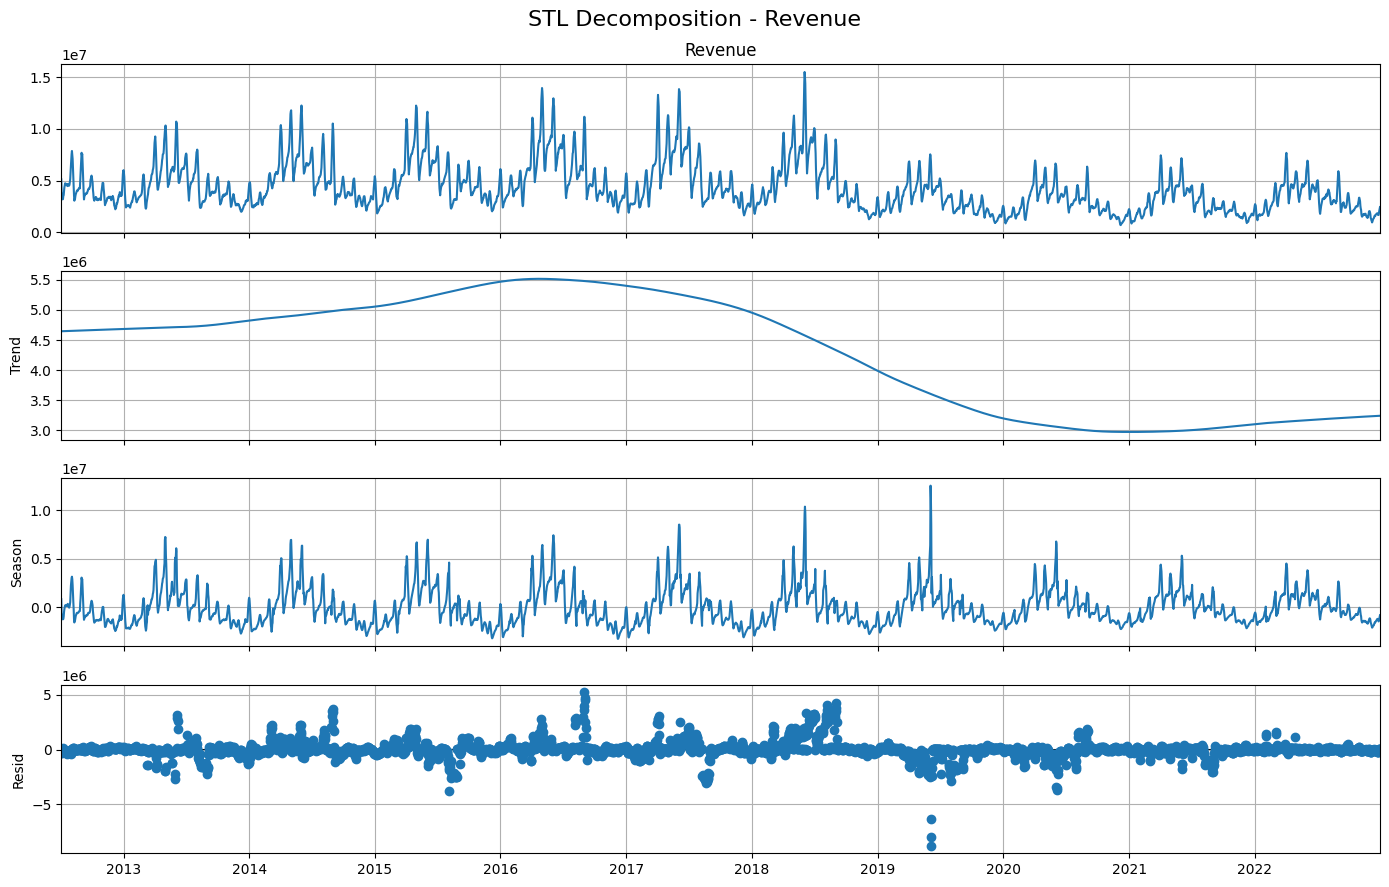

In [ ]:
# ============================================================
# BOX 4R — ĐÁNH GIÁ STL REVENUE
# ============================================================

def plot_stl_revenue(data, target_col="Revenue", period=365):
    """
    Tách Revenue thành trend, seasonal và residual.
    Mục tiêu là xem Revenue có xu hướng dài hạn, mùa vụ năm hoặc nhiễu bất thường không.
    """

    series = data[target_col].copy()

    # Làm mượt 7 ngày để giảm nhiễu daily
    series = series.rolling(7, min_periods=1).mean()

    stl = STL(series, period=period, robust=True)
    result = stl.fit()

    fig = result.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle("STL Decomposition - Revenue", fontsize=16)
    plt.tight_layout()
    plt.show()

    return result


stl_revenue = plot_stl_revenue(df_rev)

Param-sensitivity

Revenue train shape: (3412, 54)
Revenue test shape : (365, 54)

Running XGBoost sensitivity for: n_estimators
Done: n_estimators

Running XGBoost sensitivity for: learning_rate
Done: learning_rate

Running XGBoost sensitivity for: max_depth
Done: max_depth

Running XGBoost sensitivity for: min_child_weight
Done: min_child_weight

Running XGBoost sensitivity for: subsample
Done: subsample

Running XGBoost sensitivity for: colsample_bytree
Done: colsample_bytree

Running XGBoost sensitivity for: reg_alpha
Done: reg_alpha

Running XGBoost sensitivity for: reg_lambda
Done: reg_lambda

Running LightGBM sensitivity for: n_estimators
Done: n_estimators

Running LightGBM sensitivity for: learning_rate
Done: learning_rate

Running LightGBM sensitivity for: num_leaves
Done: num_leaves

Running LightGBM sensitivity for: max_depth
Done: max_depth

Running LightGBM sensitivity for: min_child_samples
Done: min_child_samples

Running LightGBM sensitivity for: subsample
Done: subsample

Running LightG

,model,parameter,value,RMSE,MAE,RMSPE,MAPE
0,XGBoost,n_estimators,100.0,760903.350194,549292.706836,32.246516,21.007941
1,XGBoost,n_estimators,200.0,728444.990925,535102.757247,29.204249,19.889079
2,XGBoost,n_estimators,300.0,716605.791773,530996.957822,28.839029,19.674621
3,XGBoost,n_estimators,400.0,712747.121387,529864.673918,28.437032,19.517913
4,XGBoost,n_estimators,500.0,709703.604873,530077.742993,28.212498,19.475528


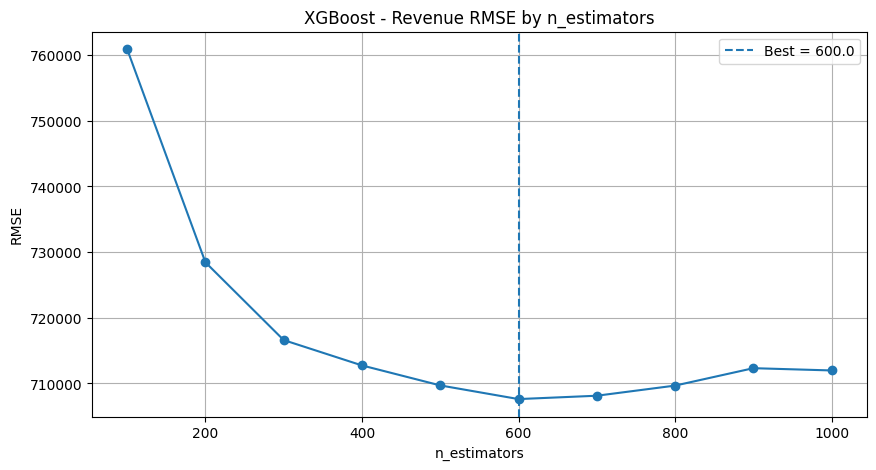

XGBoost | n_estimators | Best value: 600.0 | Best RMSE: 707,624.27


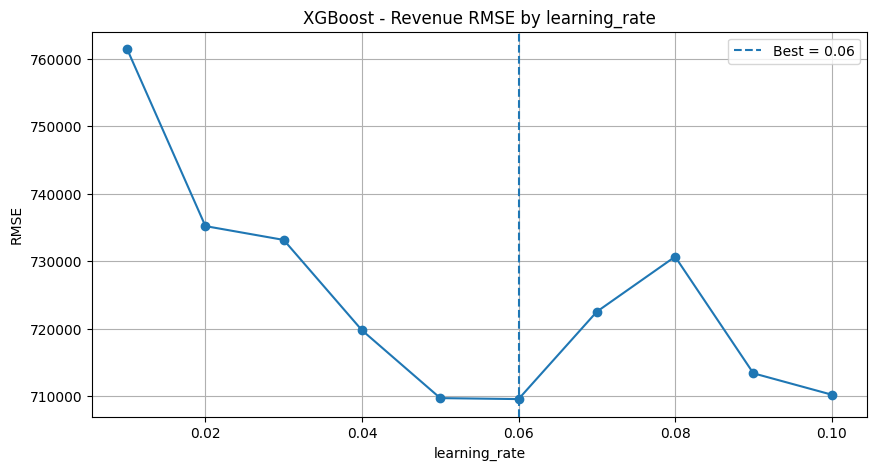

XGBoost | learning_rate | Best value: 0.06 | Best RMSE: 709,559.74


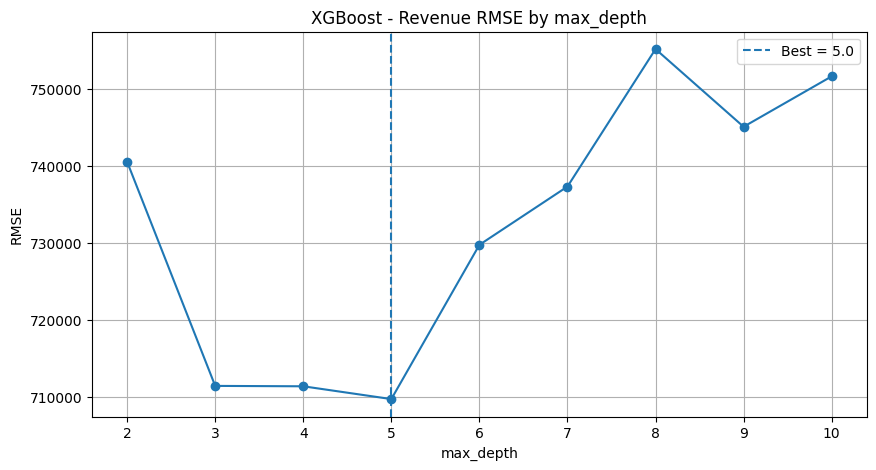

XGBoost | max_depth | Best value: 5.0 | Best RMSE: 709,703.60


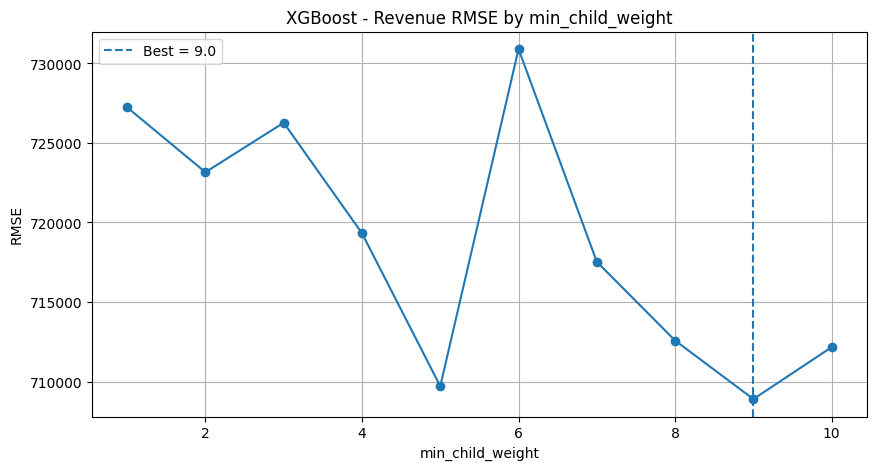

XGBoost | min_child_weight | Best value: 9.0 | Best RMSE: 708,895.69


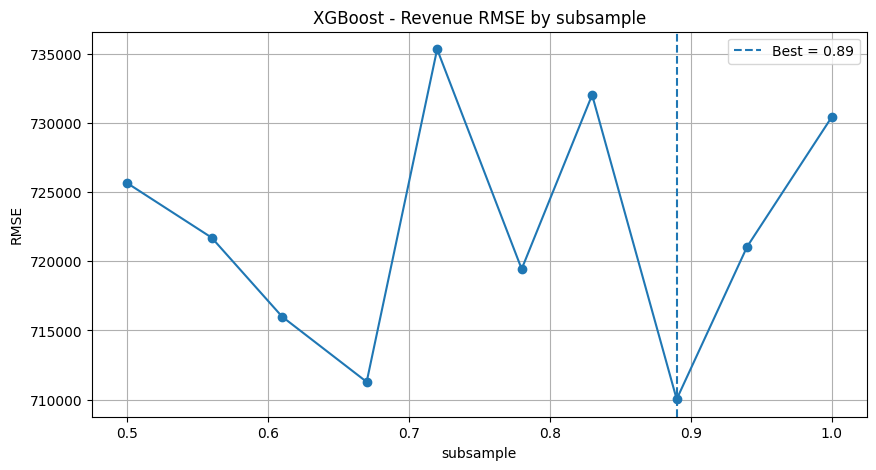

XGBoost | subsample | Best value: 0.89 | Best RMSE: 710,033.16


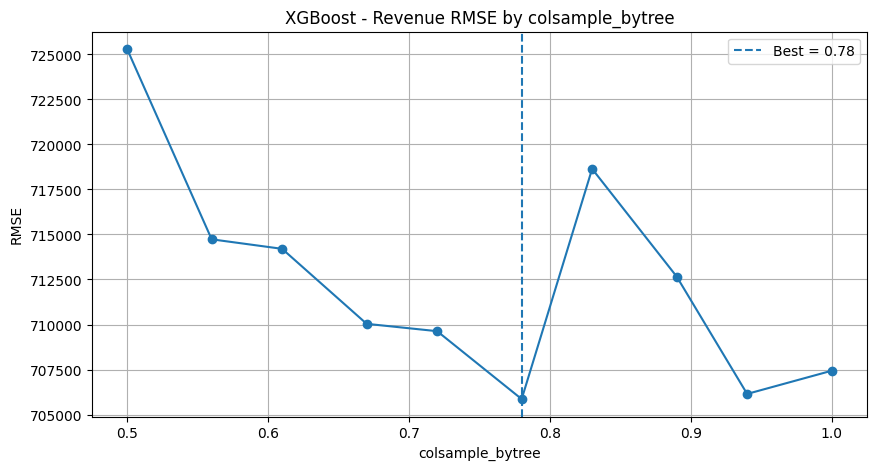

XGBoost | colsample_bytree | Best value: 0.78 | Best RMSE: 705,857.62


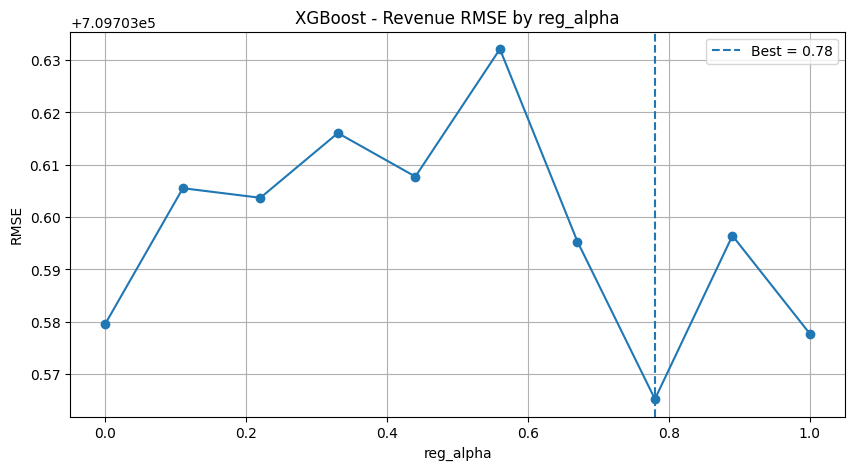

XGBoost | reg_alpha | Best value: 0.78 | Best RMSE: 709,703.57


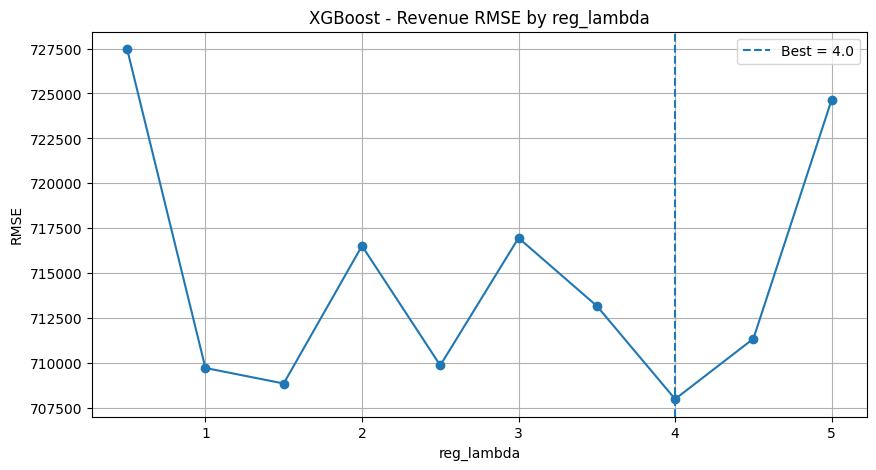

XGBoost | reg_lambda | Best value: 4.0 | Best RMSE: 707,970.65


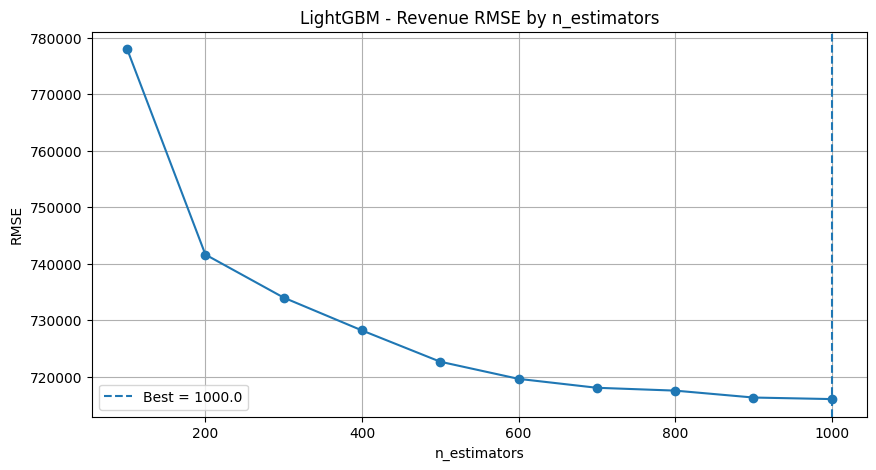

LightGBM | n_estimators | Best value: 1000.0 | Best RMSE: 716,052.68


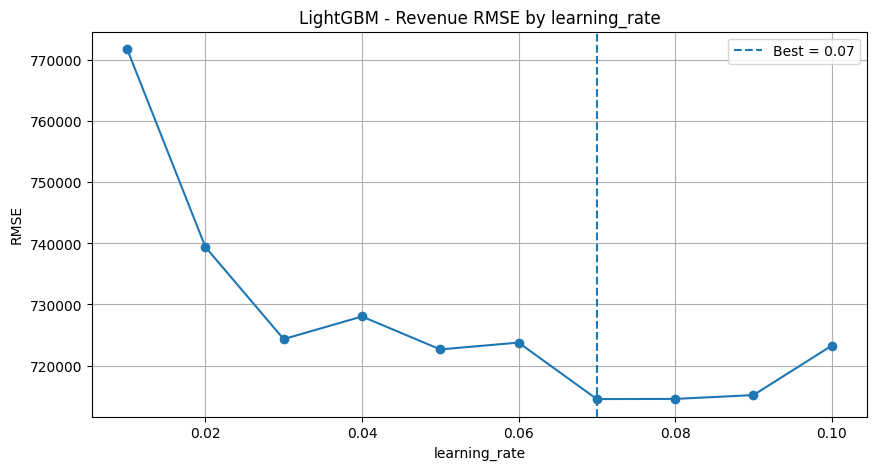

LightGBM | learning_rate | Best value: 0.07 | Best RMSE: 714,548.99


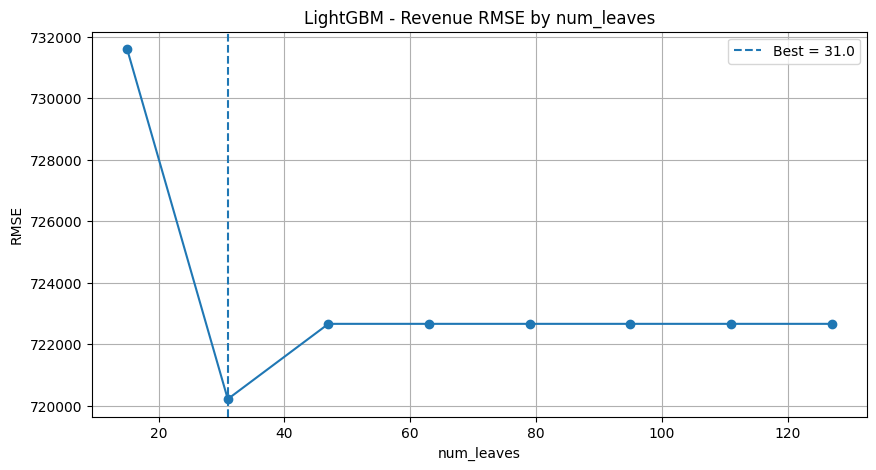

LightGBM | num_leaves | Best value: 31.0 | Best RMSE: 720,216.50


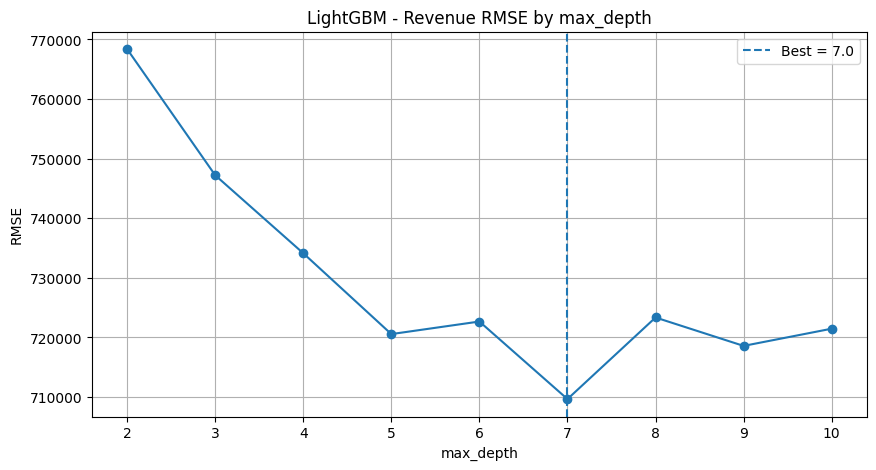

LightGBM | max_depth | Best value: 7.0 | Best RMSE: 709,648.83


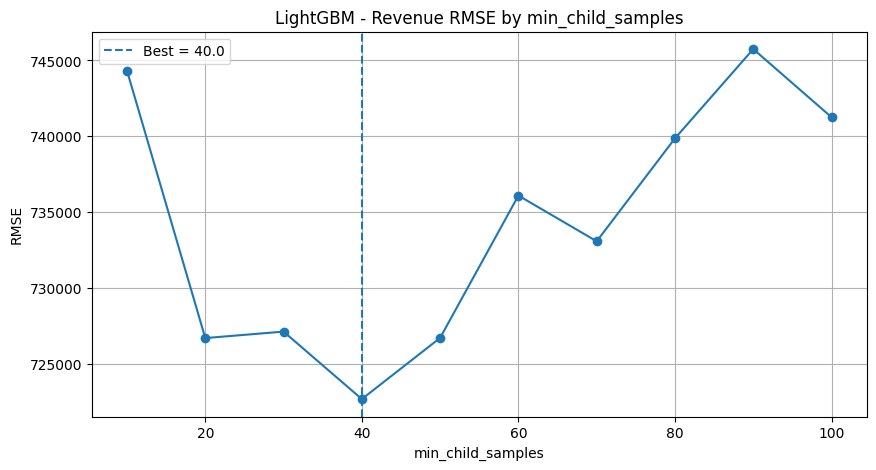

LightGBM | min_child_samples | Best value: 40.0 | Best RMSE: 722,661.76


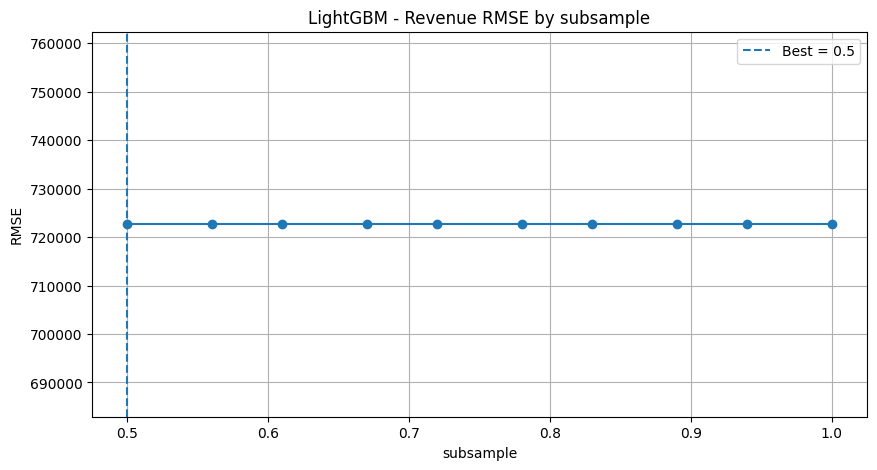

LightGBM | subsample | Best value: 0.5 | Best RMSE: 722,661.76


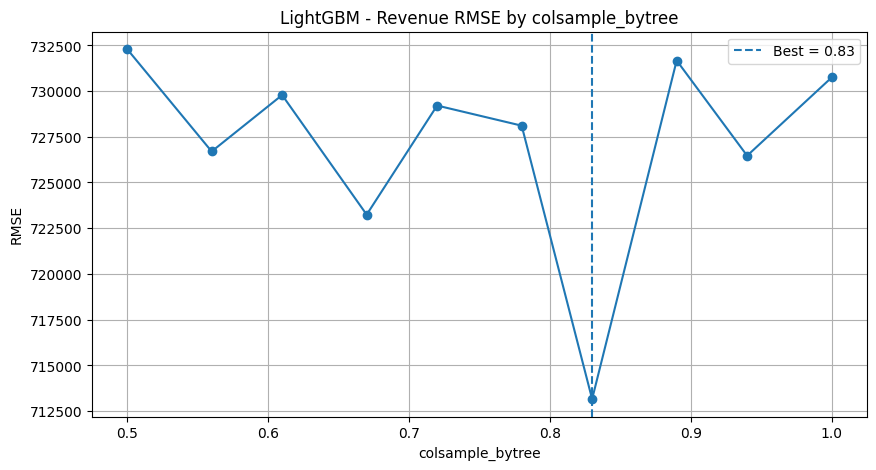

LightGBM | colsample_bytree | Best value: 0.83 | Best RMSE: 713,154.25


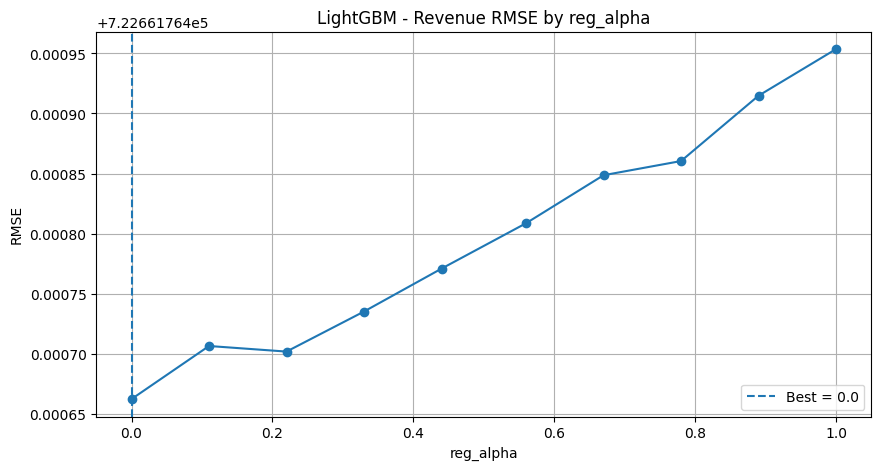

LightGBM | reg_alpha | Best value: 0.0 | Best RMSE: 722,661.76


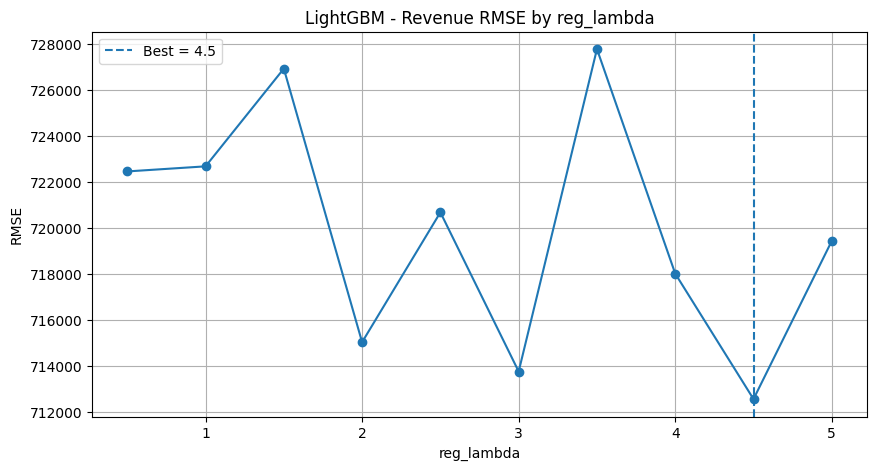

LightGBM | reg_lambda | Best value: 4.5 | Best RMSE: 712,543.37


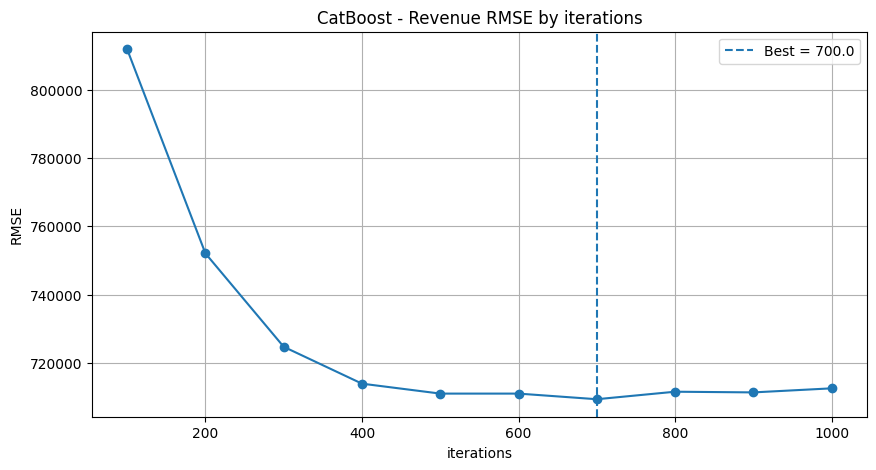

CatBoost | iterations | Best value: 700.0 | Best RMSE: 709,358.41


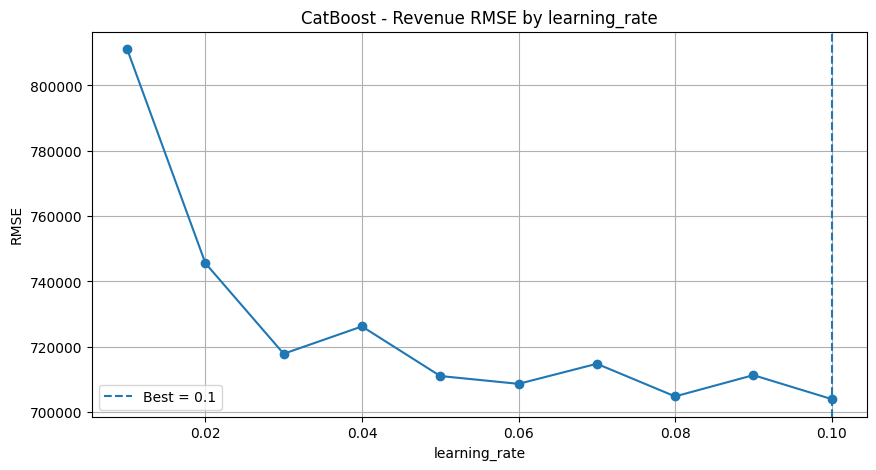

CatBoost | learning_rate | Best value: 0.1 | Best RMSE: 703,949.14


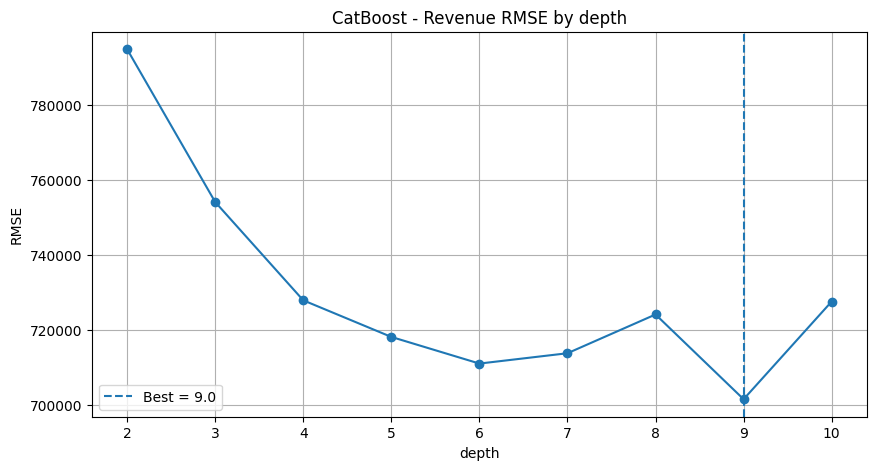

CatBoost | depth | Best value: 9.0 | Best RMSE: 701,486.11


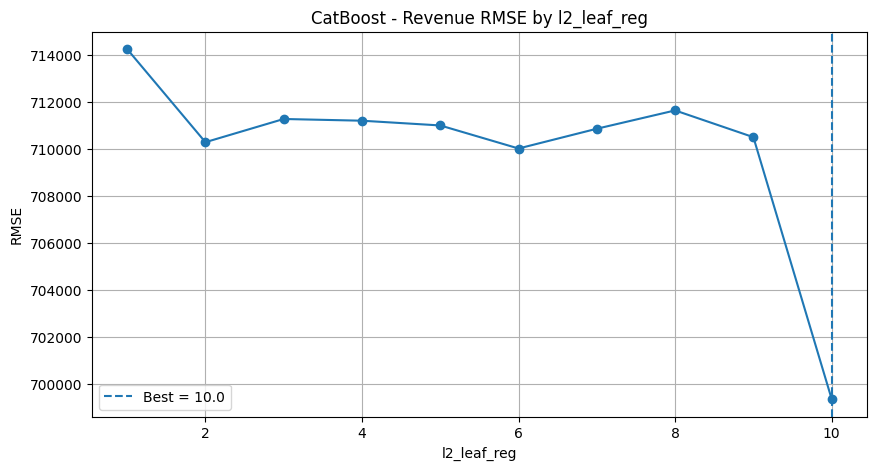

CatBoost | l2_leaf_reg | Best value: 10.0 | Best RMSE: 699,341.64


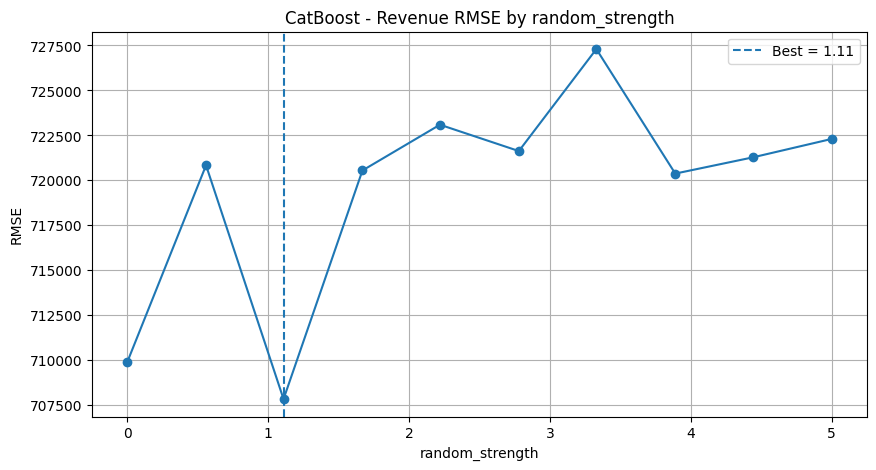

CatBoost | random_strength | Best value: 1.11 | Best RMSE: 707,834.01


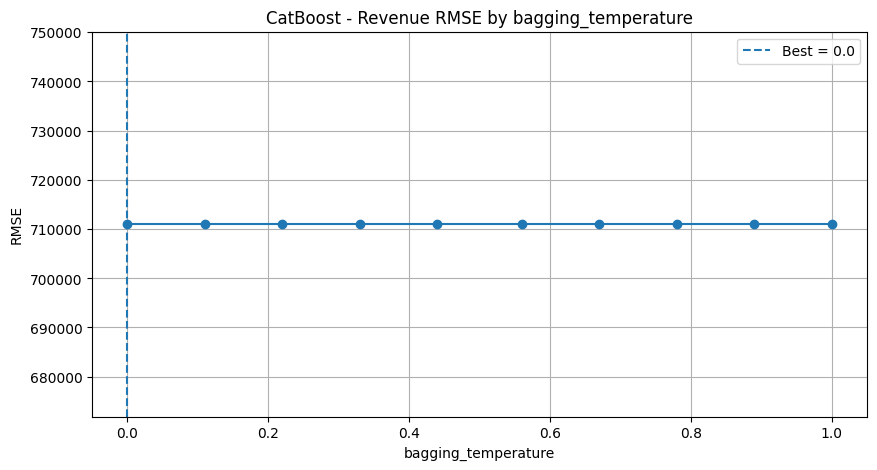

CatBoost | bagging_temperature | Best value: 0.0 | Best RMSE: 711,006.12


,model,parameter,value,RMSE,MAE,RMSPE,MAPE
3,CatBoost,l2_leaf_reg,10.00,699341.636888,515876.671567,27.969017,19.093593
1,CatBoost,depth,9.00,701486.106507,515963.153502,28.366133,19.007117
4,CatBoost,learning_rate,0.10,703949.136948,522480.582814,27.388348,18.984148
5,CatBoost,random_strength,1.11,707834.009104,515939.560761,28.302161,19.110889
2,CatBoost,iterations,700.00,709358.405503,526055.539782,28.117302,19.274534
0,CatBoost,bagging_temperature,0.00,711006.122713,525067.939276,28.362497,19.366209
8,LightGBM,max_depth,7.00,709648.825969,525639.532273,27.566837,19.034330
13,LightGBM,reg_lambda,4.50,712543.368091,527693.459189,28.091483,19.272992
6,LightGBM,colsample_bytree,0.83,713154.245852,528588.297383,28.365051,19.328369
7,LightGBM,learning_rate,0.07,714548.990411,530790.851607,27.786172,19.250668


,model,parameter,suggested_values,best_value,best_rmse
0,CatBoost,bagging_temperature,"[0.0, 0.11, 0.22]",0.00,711006.122713
1,CatBoost,depth,"[9.0, 6.0, 7.0]",9.00,701486.106507
2,CatBoost,iterations,"[700.0, 600.0, 500.0]",700.00,709358.405503
3,CatBoost,l2_leaf_reg,"[10.0, 6.0, 2.0]",10.00,699341.636888
4,CatBoost,learning_rate,"[0.1, 0.08, 0.06]",0.10,703949.136948
5,CatBoost,random_strength,"[1.11, 0.0, 3.89]",1.11,707834.009104
6,LightGBM,colsample_bytree,"[0.83, 0.67, 0.94]",0.83,713154.245852
7,LightGBM,learning_rate,"[0.07, 0.08, 0.09]",0.07,714548.990411
8,LightGBM,max_depth,"[7.0, 9.0, 5.0]",7.00,709648.825969
9,LightGBM,min_child_samples,"[40.0, 20.0, 50.0]",40.00,722661.764699


In [ ]:
# ============================================================
# BOX 5R — PARAMETER SENSITIVITY ANALYSIS — REVENUE
# Mục tiêu:
# - Mỗi lần chỉ thay đổi 1 hyperparameter
# - Các hyperparameter còn lại giữ baseline
# - Đo RMSE trên holdout 2022
# - Vẽ biểu đồ đường để giải thích vì sao chọn khoảng grid search
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

def make_revenue_features(data):
    """
    Tạo feature riêng cho Revenue.
    Feature gồm calendar, cyclic, lag, rolling, momentum và Fourier.
    """

    data = data.copy().sort_index()
    target_col = "Revenue"

    # Calendar features
    data["dow"] = data.index.dayofweek
    data["weekofyear"] = data.index.isocalendar().week.astype(int)
    data["month"] = data.index.month
    data["quarter"] = data.index.quarter
    data["dayofmonth"] = data.index.day
    data["dayofyear"] = data.index.dayofyear
    data["year"] = data.index.year

    data["is_weekend"] = (data["dow"] >= 5).astype(int)
    data["is_month_start"] = data.index.is_month_start.astype(int)
    data["is_month_end"] = data.index.is_month_end.astype(int)
    data["is_quarter_start"] = data.index.is_quarter_start.astype(int)
    data["is_quarter_end"] = data.index.is_quarter_end.astype(int)

    # Cyclical features
    data["dow_sin"] = np.sin(2 * np.pi * data["dow"] / 7)
    data["dow_cos"] = np.cos(2 * np.pi * data["dow"] / 7)

    data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
    data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

    data["doy_sin"] = np.sin(2 * np.pi * data["dayofyear"] / 365.25)
    data["doy_cos"] = np.cos(2 * np.pi * data["dayofyear"] / 365.25)

    # Lag features
    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"rev_lag_{lag}"] = data[target_col].shift(lag)

    # Rolling features
    for w in [7, 14, 28, 56]:
        data[f"rev_roll_mean_{w}"] = data[target_col].shift(1).rolling(w).mean()
        data[f"rev_roll_std_{w}"]  = data[target_col].shift(1).rolling(w).std()
        data[f"rev_roll_min_{w}"]  = data[target_col].shift(1).rolling(w).min()
        data[f"rev_roll_max_{w}"]  = data[target_col].shift(1).rolling(w).max()

    # Momentum features
    data["rev_diff_1"]  = data[target_col].shift(1) - data[target_col].shift(2)
    data["rev_diff_7"]  = data[target_col].shift(1) - data[target_col].shift(8)
    data["rev_ratio_7"] = data[target_col].shift(1) / (data[target_col].shift(8) + 1e-6)

    # Fourier features
    fourier_weekly = add_fourier_terms(data.index, 7, 2, "rev_fourier_w")
    fourier_yearly = add_fourier_terms(data.index, 365.25, 3, "rev_fourier_y")

    data = pd.concat([data, fourier_weekly, fourier_yearly], axis=1)

    data["target"] = data[target_col]

    return data

# ============================================================
# 1) CHUẨN BỊ DATA REVENUE CHO HOLDOUT 2022
# ============================================================

def prepare_revenue_holdout(df_rev, split_date="2022-01-01"):
    """
    Tạo tập train/test cho Revenue:
    - Train: trước năm 2022
    - Test: năm 2022
    """

    daily_ml = make_revenue_features(df_rev).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["Revenue", "target"]
    ]

    train_df = daily_ml[daily_ml.index < split_date].copy()
    test_df  = daily_ml[daily_ml.index >= split_date].copy()

    X_train = train_df[feature_cols]
    y_train = train_df["target"]

    X_test = test_df[feature_cols]
    y_test = test_df["target"]

    return X_train, y_train, X_test, y_test, feature_cols


X_train_rev, y_train_rev, X_test_rev, y_test_rev, revenue_feature_cols = prepare_revenue_holdout(df_rev)

print("Revenue train shape:", X_train_rev.shape)
print("Revenue test shape :", X_test_rev.shape)


# ============================================================
# 2) METRIC
# ============================================================

def safe_mape(y_true, y_pred):
    """
    MAPE bỏ qua actual = 0 để tránh lỗi chia cho 0.
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def safe_rmspe(y_true, y_pred):
    """
    RMSPE dùng như chỉ số phụ để quan sát sai số tương đối.
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2)) * 100


def evaluate_revenue_pred(y_true, y_pred):
    """
    Chỉ số chính: RMSE, MAE
    Chỉ số phụ: RMSPE, MAPE
    """

    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSPE": safe_rmspe(y_true, y_pred),
        "MAPE": safe_mape(y_true, y_pred)
    }


# ============================================================
# 3) BASELINE PARAMS CHO TỪNG MODEL
# ============================================================

xgb_base_params = {
    "objective": "reg:squarederror",
    "random_state": 42,
    "tree_method": "hist",
    "verbosity": 0,
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 5,
    "min_child_weight": 5,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0
}

lgbm_base_params = {
    "objective": "regression",
    "random_state": 42,
    "verbose": -1,
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "max_depth": 6,
    "min_child_samples": 40,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0
}

cat_base_params = {
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": False,
    "iterations": 500,
    "learning_rate": 0.05,
    "depth": 6,
    "l2_leaf_reg": 5,
    "random_strength": 1,
    "bagging_temperature": 0.5
}


# ============================================================
# 4) PARAMETER RANGE ĐỂ TEST
# Mỗi tham số chạy khoảng 8-10 giá trị
# ============================================================

xgb_param_ranges = {
    "n_estimators": list(range(100, 1100, 100)),
    "learning_rate": np.round(np.linspace(0.01, 0.10, 10), 3).tolist(),
    "max_depth": list(range(2, 11)),
    "min_child_weight": list(range(1, 11)),
    "subsample": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "colsample_bytree": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "reg_alpha": np.round(np.linspace(0.0, 1.0, 10), 2).tolist(),
    "reg_lambda": np.round(np.linspace(0.5, 5.0, 10), 2).tolist()
}

lgbm_param_ranges = {
    "n_estimators": list(range(100, 1100, 100)),
    "learning_rate": np.round(np.linspace(0.01, 0.10, 10), 3).tolist(),
    "num_leaves": [15, 31, 47, 63, 79, 95, 111, 127],
    "max_depth": list(range(2, 11)),
    "min_child_samples": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "subsample": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "colsample_bytree": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "reg_alpha": np.round(np.linspace(0.0, 1.0, 10), 2).tolist(),
    "reg_lambda": np.round(np.linspace(0.5, 5.0, 10), 2).tolist()
}

cat_param_ranges = {
    "iterations": list(range(100, 1100, 100)),
    "learning_rate": np.round(np.linspace(0.01, 0.10, 10), 3).tolist(),
    "depth": list(range(2, 11)),
    "l2_leaf_reg": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "random_strength": np.round(np.linspace(0.0, 5.0, 10), 2).tolist(),
    "bagging_temperature": np.round(np.linspace(0.0, 1.0, 10), 2).tolist()
}


# ============================================================
# 5) HÀM CHẠY SENSITIVITY CHO 1 MODEL
# ============================================================

def run_param_sensitivity(
    model_name,
    model_class,
    base_params,
    param_ranges,
    X_train,
    y_train,
    X_test,
    y_test
):
    """
    Chạy sensitivity analysis cho từng hyperparameter.
    Mỗi lần chỉ thay đổi 1 tham số.
    """

    all_results = []

    for param_name, values in param_ranges.items():
        print(f"\nRunning {model_name} sensitivity for: {param_name}")

        for value in values:
            params = base_params.copy()
            params[param_name] = value

            model = model_class(**params)
            model.fit(X_train, y_train)

            pred = model.predict(X_test)
            pred = np.clip(pred, 0, None)

            metrics = evaluate_revenue_pred(y_test, pred)

            all_results.append({
                "model": model_name,
                "parameter": param_name,
                "value": value,
                "RMSE": metrics["RMSE"],
                "MAE": metrics["MAE"],
                "RMSPE": metrics["RMSPE"],
                "MAPE": metrics["MAPE"]
            })

        print(f"Done: {param_name}")

    results_df = pd.DataFrame(all_results)

    return results_df


# ============================================================
# 6) CHẠY SENSITIVITY CHO 3 MODEL — REVENUE
# ============================================================

xgb_sensitivity_rev = run_param_sensitivity(
    model_name="XGBoost",
    model_class=XGBRegressor,
    base_params=xgb_base_params,
    param_ranges=xgb_param_ranges,
    X_train=X_train_rev,
    y_train=y_train_rev,
    X_test=X_test_rev,
    y_test=y_test_rev
)

lgbm_sensitivity_rev = run_param_sensitivity(
    model_name="LightGBM",
    model_class=LGBMRegressor,
    base_params=lgbm_base_params,
    param_ranges=lgbm_param_ranges,
    X_train=X_train_rev,
    y_train=y_train_rev,
    X_test=X_test_rev,
    y_test=y_test_rev
)

cat_sensitivity_rev = run_param_sensitivity(
    model_name="CatBoost",
    model_class=CatBoostRegressor,
    base_params=cat_base_params,
    param_ranges=cat_param_ranges,
    X_train=X_train_rev,
    y_train=y_train_rev,
    X_test=X_test_rev,
    y_test=y_test_rev
)


# ============================================================
# 7) GỘP KẾT QUẢ
# ============================================================

revenue_sensitivity_results = pd.concat(
    [
        xgb_sensitivity_rev,
        lgbm_sensitivity_rev,
        cat_sensitivity_rev
    ],
    axis=0
).reset_index(drop=True)

display(revenue_sensitivity_results.head())


# ============================================================
# 8) VẼ BIỂU ĐỒ RMSE THEO TỪNG PARAMETER
# ============================================================

def plot_param_sensitivity(results_df, model_name):
    """
    Vẽ từng biểu đồ riêng cho từng tham số.
    Trục X: giá trị tham số
    Trục Y: RMSE
    """

    model_df = results_df[results_df["model"] == model_name].copy()

    for param_name in model_df["parameter"].unique():
        temp = model_df[model_df["parameter"] == param_name].copy()
        temp = temp.sort_values("value")

        best_row = temp.loc[temp["RMSE"].idxmin()]

        plt.figure(figsize=(10, 5))
        plt.plot(temp["value"], temp["RMSE"], marker="o")
        plt.axvline(best_row["value"], linestyle="--", label=f"Best = {best_row['value']}")
        plt.title(f"{model_name} - Revenue RMSE by {param_name}")
        plt.xlabel(param_name)
        plt.ylabel("RMSE")
        plt.legend()
        plt.grid(True)
        plt.show()

        print(
            f"{model_name} | {param_name} | "
            f"Best value: {best_row['value']} | "
            f"Best RMSE: {best_row['RMSE']:,.2f}"
        )


plot_param_sensitivity(revenue_sensitivity_results, "XGBoost")
plot_param_sensitivity(revenue_sensitivity_results, "LightGBM")
plot_param_sensitivity(revenue_sensitivity_results, "CatBoost")


# ============================================================
# 9) BẢNG BEST VALUE CHO MỖI PARAMETER
# ============================================================

best_param_summary_rev = (
    revenue_sensitivity_results
    .sort_values("RMSE")
    .groupby(["model", "parameter"], as_index=False)
    .first()
    .sort_values(["model", "RMSE"])
)

display(best_param_summary_rev)


# ============================================================
# 10) GỢI Ý GRID SEARCH HẸP TỪ SENSITIVITY
# ============================================================

def suggest_grid_from_sensitivity(results_df, top_k=3):
    """
    Gợi ý vùng grid search hẹp:
    - Lấy top_k giá trị có RMSE thấp nhất cho mỗi parameter
    - Dùng bảng này để giải thích vì sao chọn grid chính thức
    """

    suggested_rows = []

    for (model, param), group in results_df.groupby(["model", "parameter"]):
        temp = group.sort_values("RMSE").head(top_k)

        suggested_rows.append({
            "model": model,
            "parameter": param,
            "suggested_values": list(temp["value"]),
            "best_value": temp.iloc[0]["value"],
            "best_rmse": temp.iloc[0]["RMSE"]
        })

    suggested_df = pd.DataFrame(suggested_rows)
    return suggested_df.sort_values(["model", "parameter"]).reset_index(drop=True)


suggested_grid_rev = suggest_grid_from_sensitivity(revenue_sensitivity_results, top_k=3)

display(suggested_grid_rev)

### 1.3. Feature Engieering

In [ ]:
# ============================================================
# BOX 6R — FEATURE ENGINEERING REVENUE
# ============================================================

def add_fourier_terms(index, period, K, prefix):
    """
    Tạo Fourier terms để model học mùa vụ tuần và mùa vụ năm.
    """

    out = pd.DataFrame(index=index)
    t = np.arange(len(index))

    for k in range(1, K + 1):
        out[f"{prefix}_sin_{k}"] = np.sin(2 * np.pi * k * t / period)
        out[f"{prefix}_cos_{k}"] = np.cos(2 * np.pi * k * t / period)

    return out


def make_revenue_features(data):
    """
    Tạo feature riêng cho Revenue.
    Feature gồm calendar, cyclic, lag, rolling, momentum và Fourier.
    """

    data = data.copy().sort_index()
    target_col = "Revenue"

    # Calendar features
    data["dow"] = data.index.dayofweek
    data["weekofyear"] = data.index.isocalendar().week.astype(int)
    data["month"] = data.index.month
    data["quarter"] = data.index.quarter
    data["dayofmonth"] = data.index.day
    data["dayofyear"] = data.index.dayofyear
    data["year"] = data.index.year

    data["is_weekend"] = (data["dow"] >= 5).astype(int)
    data["is_month_start"] = data.index.is_month_start.astype(int)
    data["is_month_end"] = data.index.is_month_end.astype(int)
    data["is_quarter_start"] = data.index.is_quarter_start.astype(int)
    data["is_quarter_end"] = data.index.is_quarter_end.astype(int)

    # Cyclical features
    data["dow_sin"] = np.sin(2 * np.pi * data["dow"] / 7)
    data["dow_cos"] = np.cos(2 * np.pi * data["dow"] / 7)

    data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
    data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

    data["doy_sin"] = np.sin(2 * np.pi * data["dayofyear"] / 365.25)
    data["doy_cos"] = np.cos(2 * np.pi * data["dayofyear"] / 365.25)

    # Lag features
    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"rev_lag_{lag}"] = data[target_col].shift(lag)

    # Rolling features
    for w in [7, 14, 28, 56]:
        data[f"rev_roll_mean_{w}"] = data[target_col].shift(1).rolling(w).mean()
        data[f"rev_roll_std_{w}"]  = data[target_col].shift(1).rolling(w).std()
        data[f"rev_roll_min_{w}"]  = data[target_col].shift(1).rolling(w).min()
        data[f"rev_roll_max_{w}"]  = data[target_col].shift(1).rolling(w).max()

    # Momentum features
    data["rev_diff_1"]  = data[target_col].shift(1) - data[target_col].shift(2)
    data["rev_diff_7"]  = data[target_col].shift(1) - data[target_col].shift(8)
    data["rev_ratio_7"] = data[target_col].shift(1) / (data[target_col].shift(8) + 1e-6)

    # Fourier features
    fourier_weekly = add_fourier_terms(data.index, 7, 2, "rev_fourier_w")
    fourier_yearly = add_fourier_terms(data.index, 365.25, 3, "rev_fourier_y")

    data = pd.concat([data, fourier_weekly, fourier_yearly], axis=1)

    data["target"] = data[target_col]

    return data

###1.4. Model Training

####XG Boost

In [ ]:
# ============================================================
# BOX 7R — TRAIN XGBOOST REVENUE
# ============================================================

xgb_fixed_params_rev = {
    "objective": "reg:squarederror",
    "random_state": RANDOM_STATE,
    "tree_method": "hist",
    "verbosity": 0
}

xgb_best_rev, xgb_tuning_rev, xgb_features_rev = tune_revenue_model_with_walking(
    model_name="XGBoost",
    model_class=XGBRegressor,
    param_grid=xgb_param_grid_rev,
    fixed_params=xgb_fixed_params_rev
)

print("\nTop 5 XGBoost Revenue tuning")
display(xgb_tuning_rev.head())


Tuning XGBoost for Revenue
Number of walking folds: 4
Total parameter combinations: 64
Done 5/64
Done 10/64
Done 15/64
Done 20/64
Done 25/64
Done 30/64
Done 35/64
Done 40/64
Done 45/64
Done 50/64
Done 55/64
Done 60/64
Done 64/64

Best params for XGBoost - Revenue:
{'n_estimators': 1200, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.9, 'colsample_bytree': 0.75, 'reg_alpha': 0.75, 'reg_lambda': 4}
Best mean RMSE: 684,720.93

Top 5 XGBoost Revenue tuning


,model,target,params,mean_rmse,mean_mae,mean_rmspe,mean_mape
0,XGBoost,Revenue,"{'n_estimators': 1200, 'learning_rate': 0.05, ...",684720.925514,520097.738407,33.604631,22.078503
1,XGBoost,Revenue,"{'n_estimators': 1200, 'learning_rate': 0.05, ...",684720.936734,520097.762529,33.604631,22.078504
2,XGBoost,Revenue,"{'n_estimators': 1200, 'learning_rate': 0.06, ...",686528.982373,517549.534695,33.307059,21.717090
3,XGBoost,Revenue,"{'n_estimators': 1200, 'learning_rate': 0.06, ...",686528.986966,517549.542422,33.307061,21.717091
4,XGBoost,Revenue,"{'n_estimators': 1200, 'learning_rate': 0.05, ...",687169.401527,517346.777955,33.861500,21.858016


####Light GBM

In [ ]:
# ============================================================
# BOX 8R — TRAIN LIGHTGBM REVENUE
# ============================================================

lgbm_fixed_params_rev = {
    "objective": "regression",
    "random_state": RANDOM_STATE,
    "verbose": -1
}

lgbm_best_rev, lgbm_tuning_rev, lgbm_features_rev = tune_revenue_model_with_walking(
    model_name="LightGBM",
    model_class=LGBMRegressor,
    param_grid=lgbm_param_grid_rev,
    fixed_params=lgbm_fixed_params_rev
)

print("\nTop 5 LightGBM Revenue tuning")
display(lgbm_tuning_rev.head())


Tuning LightGBM for Revenue
Number of walking folds: 4
Total parameter combinations: 54
Done 5/54
Done 10/54
Done 15/54
Done 20/54
Done 25/54
Done 30/54
Done 35/54
Done 40/54
Done 45/54
Done 50/54
Done 54/54

Best params for LightGBM - Revenue:
{'learning_rate': 0.09, 'num_leaves': 35, 'max_depth': 8, 'min_child_samples': 30, 'subsample': 0.5, 'colsample_bytree': 0.83, 'reg_alpha': 0, 'reg_lambda': 0.3}
Best mean RMSE: 712,156.23

Top 5 LightGBM Revenue tuning


,model,target,params,mean_rmse,mean_mae,mean_rmspe,mean_mape
0,LightGBM,Revenue,"{'learning_rate': 0.09, 'num_leaves': 35, 'max...",712156.231148,533679.176618,36.402925,22.625962
1,LightGBM,Revenue,"{'learning_rate': 0.09, 'num_leaves': 30, 'max...",713780.388736,530827.178150,35.883730,22.508580
2,LightGBM,Revenue,"{'learning_rate': 0.09, 'num_leaves': 30, 'max...",713858.281954,533948.203544,35.507952,22.597946
3,LightGBM,Revenue,"{'learning_rate': 0.09, 'num_leaves': 35, 'max...",714208.283338,533624.500594,36.356834,22.646348
4,LightGBM,Revenue,"{'learning_rate': 0.09, 'num_leaves': 35, 'max...",715095.198801,537291.530777,35.476143,22.711760


####CatBoost

In [ ]:
# ============================================================
# BOX 9R — TRAIN CATBOOST REVENUE
# ============================================================

cat_fixed_params_rev = {
    "loss_function": "RMSE",
    "random_seed": RANDOM_STATE,
    "verbose": False
}

cat_best_rev, cat_tuning_rev, cat_features_rev = tune_revenue_model_with_walking(
    model_name="CatBoost",
    model_class=CatBoostRegressor,
    param_grid=cat_param_grid_rev,
    fixed_params=cat_fixed_params_rev
)

print("\nTop 5 CatBoost Revenue tuning")
display(cat_tuning_rev.head())


Tuning CatBoost for Revenue
Number of walking folds: 4
Total parameter combinations: 36
Done 5/36
Done 10/36
Done 15/36
Done 20/36
Done 25/36
Done 30/36
Done 35/36
Done 36/36

Best params for CatBoost - Revenue:
{'iterations': 700, 'learning_rate': 0.1, 'depth': 6, 'l2_leaf_reg': 10, 'random_strength': 0, 'bagging_temperature': 0}
Best mean RMSE: 686,449.10

Top 5 CatBoost Revenue tuning


,model,target,params,mean_rmse,mean_mae,mean_rmspe,mean_mape
0,CatBoost,Revenue,"{'iterations': 700, 'learning_rate': 0.1, 'dep...",686449.097436,517431.225828,34.847514,22.050391
1,CatBoost,Revenue,"{'iterations': 600, 'learning_rate': 0.1, 'dep...",687250.999014,517357.344783,34.839337,22.078248
2,CatBoost,Revenue,"{'iterations': 800, 'learning_rate': 0.1, 'dep...",688919.322211,520006.104223,35.061448,22.204577
3,CatBoost,Revenue,"{'iterations': 800, 'learning_rate': 0.06, 'de...",689135.386616,517287.879132,34.283953,21.936333
4,CatBoost,Revenue,"{'iterations': 700, 'learning_rate': 0.06, 'de...",690572.924799,518481.000376,34.392548,21.975933


###1.5. Model Evaluation


XGBoost - Revenue HOLDOUT 2022
RMSE : 695,215.71
MAE  : 518,796.64
RMSPE: 26.41%
MAPE : 18.73%


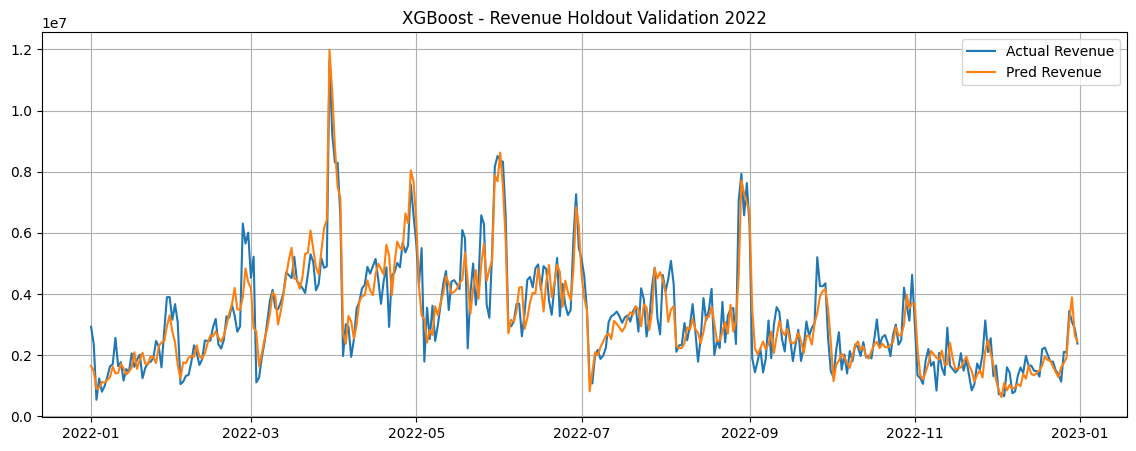


LightGBM - Revenue HOLDOUT 2022
RMSE : 757,902.79
MAE  : 561,891.92
RMSPE: 30.87%
MAPE : 20.66%


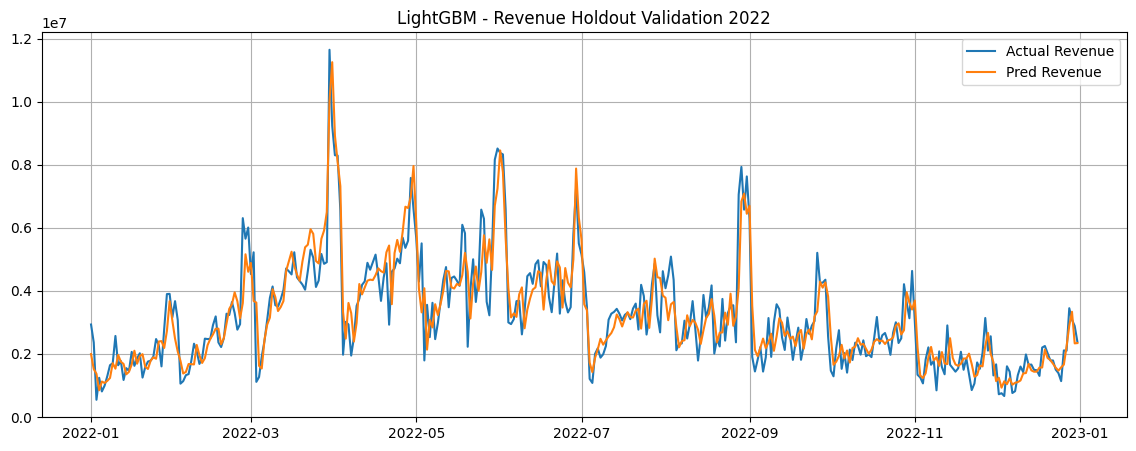


CatBoost - Revenue HOLDOUT 2022
RMSE : 705,936.20
MAE  : 522,749.16
RMSPE: 27.09%
MAPE : 18.80%


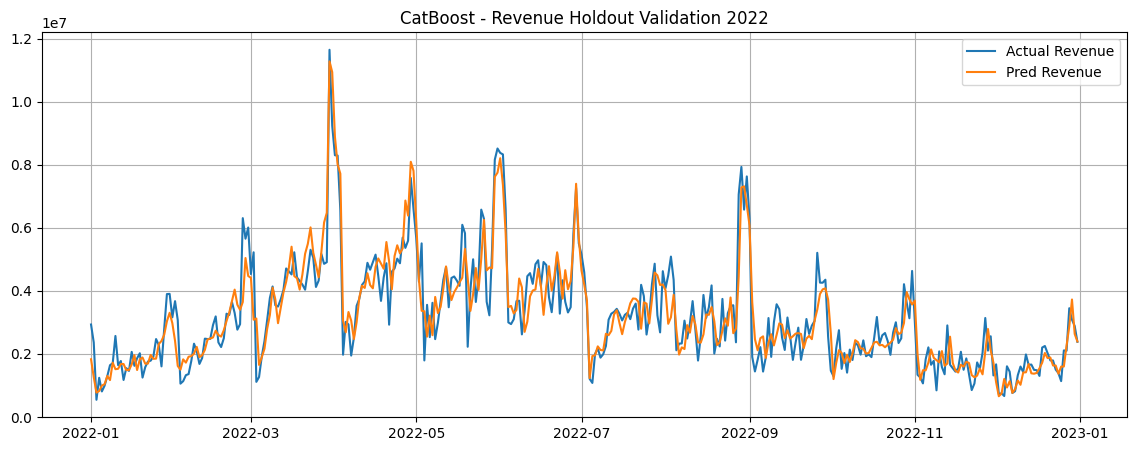

,model,target,RMSE,MAE,RMSPE,MAPE
0,XGBoost,Revenue,695215.707893,518796.641212,26.405228,18.728603
1,CatBoost,Revenue,705936.202418,522749.164753,27.094357,18.800652
2,LightGBM,Revenue,757902.793004,561891.916405,30.865163,20.657387



BEST REVENUE MODEL
XGBoost
{'RMSE': np.float64(695215.7078933001), 'MAE': 518796.6412123288, 'RMSPE': np.float64(26.405227820505562), 'MAPE': np.float64(18.72860315480794)}


In [ ]:
# ============================================================
# BOX 10R — MODEL EVALUATION REVENUE
# ============================================================

def evaluate_revenue_model(model_name, model_class, best_params, fixed_params):
    """
    Đánh giá Revenue trên holdout 2022.
    Sau đó lưu model, metric và feature importance.
    """

    daily_ml = make_revenue_features(df_rev).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["Revenue", "target"]
    ]

    split_date = "2022-01-01"

    train_df = daily_ml[daily_ml.index < split_date].copy()
    test_df = daily_ml[daily_ml.index >= split_date].copy()

    X_train = train_df[feature_cols]
    y_train = train_df["target"]

    X_test = test_df[feature_cols]
    y_test = test_df["target"]

    model = model_class(**fixed_params, **best_params)
    model.fit(X_train, y_train)

    test_pred = model.predict(X_test)
    test_pred = np.clip(test_pred, 0, None)

    metrics = evaluate_prediction(y_test, test_pred)

    print(f"\n{model_name} - Revenue HOLDOUT 2022")
    print(f"RMSE : {metrics['RMSE']:,.2f}")
    print(f"MAE  : {metrics['MAE']:,.2f}")
    print(f"RMSPE: {metrics['RMSPE']:.2f}%")
    print(f"MAPE : {metrics['MAPE']:.2f}%")

    plt.figure(figsize=(14, 5))
    plt.plot(test_df.index, y_test, label="Actual Revenue")
    plt.plot(test_df.index, test_pred, label="Pred Revenue")
    plt.title(f"{model_name} - Revenue Holdout Validation 2022")
    plt.legend()
    plt.show()

    fi = pd.DataFrame({
        "feature": feature_cols,
        "importance": model.feature_importances_
    }).sort_values("importance", ascending=False)

    return {
        "model_name": model_name,
        "target": "Revenue",
        "model_class": model_class,
        "best_params": best_params,
        "fixed_params": fixed_params,
        "model": model,
        "metrics": metrics,
        "test_df": test_df,
        "test_pred": test_pred,
        "feature_cols": feature_cols,
        "fi": fi
    }


revenue_eval_results = []

revenue_eval_results.append(
    evaluate_revenue_model(
        "XGBoost",
        XGBRegressor,
        xgb_best_rev,
        xgb_fixed_params_rev
    )
)

revenue_eval_results.append(
    evaluate_revenue_model(
        "LightGBM",
        LGBMRegressor,
        lgbm_best_rev,
        lgbm_fixed_params_rev
    )
)

revenue_eval_results.append(
    evaluate_revenue_model(
        "CatBoost",
        CatBoostRegressor,
        cat_best_rev,
        cat_fixed_params_rev
    )
)

revenue_eval_summary = pd.DataFrame([
    {
        "model": r["model_name"],
        "target": r["target"],
        "RMSE": r["metrics"]["RMSE"],
        "MAE": r["metrics"]["MAE"],
        "RMSPE": r["metrics"]["RMSPE"],
        "MAPE": r["metrics"]["MAPE"]
    }
    for r in revenue_eval_results
]).sort_values("RMSE").reset_index(drop=True)

display(revenue_eval_summary)

# Chọn model Revenue tốt nhất theo RMSE
best_revenue_result = revenue_eval_results[
    np.argmin([r["metrics"]["RMSE"] for r in revenue_eval_results])
]

print("\nBEST REVENUE MODEL")
print(best_revenue_result["model_name"])
print(best_revenue_result["metrics"])

###1.6. Model Integration


Top Revenue features


,feature,importance
18,rev_lag_1,0.385636
31,rev_roll_min_14,0.159601
27,rev_roll_min_7,0.059941
4,dayofmonth,0.035241
21,rev_lag_7,0.021523
24,rev_lag_28,0.018138
16,doy_sin,0.015423
45,rev_fourier_w_cos_1,0.014922
29,rev_roll_mean_14,0.014749
53,rev_fourier_y_cos_3,0.013113


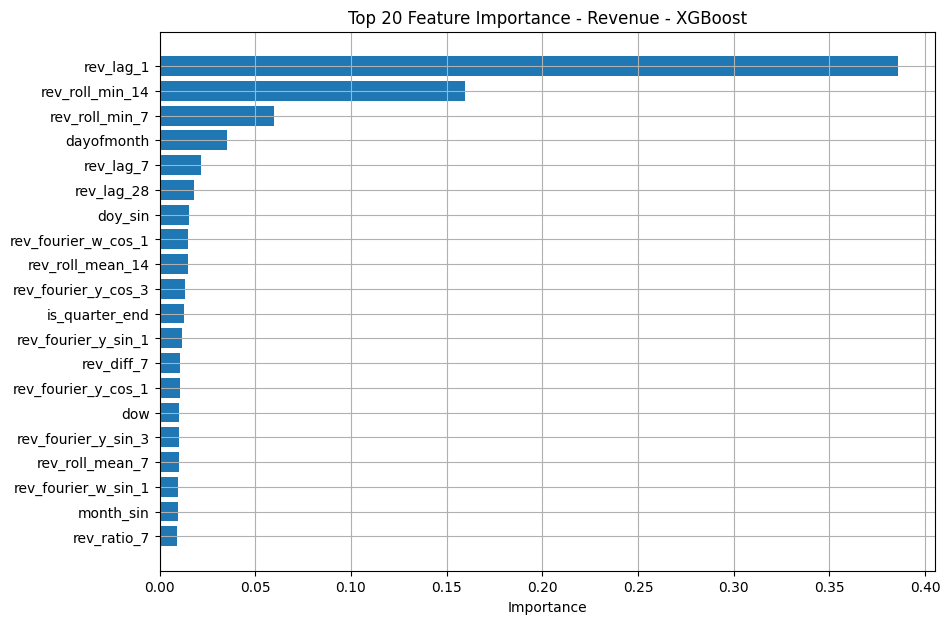

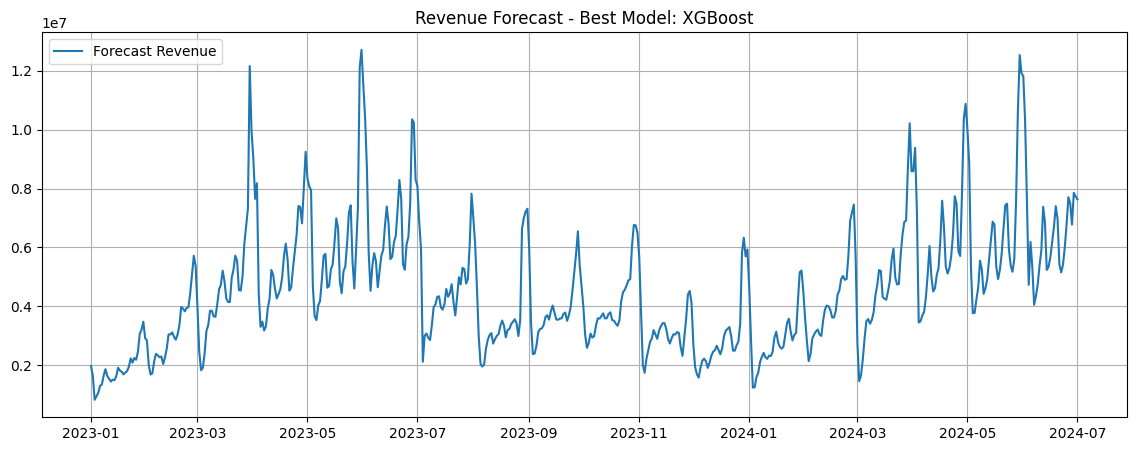

,Date,Revenue
0,2023-01-01,1.973441e+06
1,2023-01-02,1.634760e+06
2,2023-01-03,8.273451e+05
3,2023-01-04,9.422176e+05
4,2023-01-05,1.060890e+06


,Date,Revenue
543,2024-06-27,7504147.5
544,2024-06-28,6780410.5
545,2024-06-29,7856684.0
546,2024-06-30,7735415.5
547,2024-07-01,7636927.5


In [ ]:
# ============================================================
# BOX 11R — FEATURE IMPORTANCE & FORECAST REVENUE
# ============================================================

def plot_revenue_feature_importance(result, top_n=20):
    """
    Vẽ feature importance của model Revenue tốt nhất.
    """

    fi = result["fi"].head(top_n).copy()
    fi = fi.sort_values("importance")

    plt.figure(figsize=(10, 7))
    plt.barh(fi["feature"], fi["importance"])
    plt.title(f"Top {top_n} Feature Importance - Revenue - {result['model_name']}")
    plt.xlabel("Importance")
    plt.show()


def forecast_revenue_with_best_model(best_result):
    """
    Train lại Revenue model tốt nhất trên toàn bộ dữ liệu 2012-2022.
    Sau đó forecast recursive cho giai đoạn 2023-01-01 đến 2024-07-01.
    """

    model_class = best_result["model_class"]
    fixed_params = best_result["fixed_params"]
    best_params = best_result["best_params"]

    daily_ml = make_revenue_features(df_rev).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["Revenue", "target"]
    ]

    X_full = daily_ml[feature_cols]
    y_full = daily_ml["target"]

    final_model = model_class(**fixed_params, **best_params)
    final_model.fit(X_full, y_full)

    future_dates = pd.date_range(forecast_start, forecast_end, freq="D")
    history = df_rev[["Revenue"]].copy()

    preds = []

    for dt in future_dates:
        new_row = pd.DataFrame(index=[dt], data={"Revenue": [np.nan]})
        temp = pd.concat([history, new_row])

        temp_feat = make_revenue_features(temp)
        pred = final_model.predict(temp_feat.loc[[dt], feature_cols])[0]
        pred = max(pred, 0)

        preds.append(pred)

        new_row["Revenue"] = pred
        history = pd.concat([history, new_row])

    revenue_forecast = pd.DataFrame({
        "Date": future_dates,
        "Revenue": preds
    })

    plt.figure(figsize=(14, 5))
    plt.plot(revenue_forecast["Date"], revenue_forecast["Revenue"], label="Forecast Revenue")
    plt.title(f"Revenue Forecast - Best Model: {best_result['model_name']}")
    plt.legend()
    plt.show()

    return revenue_forecast, final_model


print("\nTop Revenue features")
display(best_revenue_result["fi"].head(20))

plot_revenue_feature_importance(best_revenue_result, top_n=20)

revenue_forecast, final_revenue_model = forecast_revenue_with_best_model(best_revenue_result)

display(revenue_forecast.head())
display(revenue_forecast.tail())

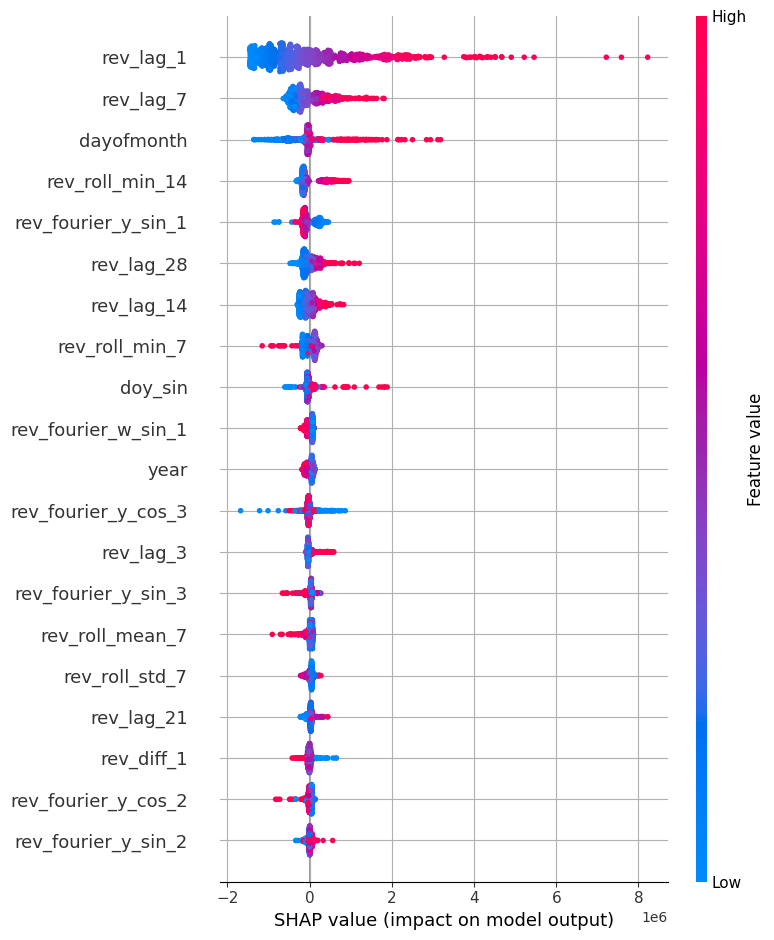

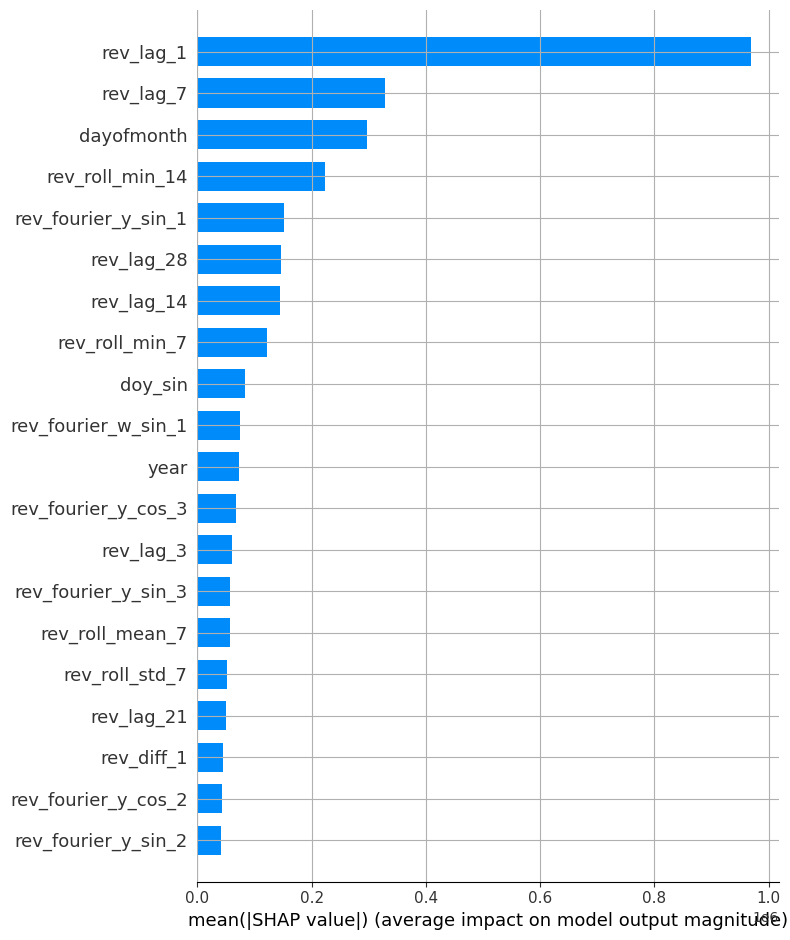

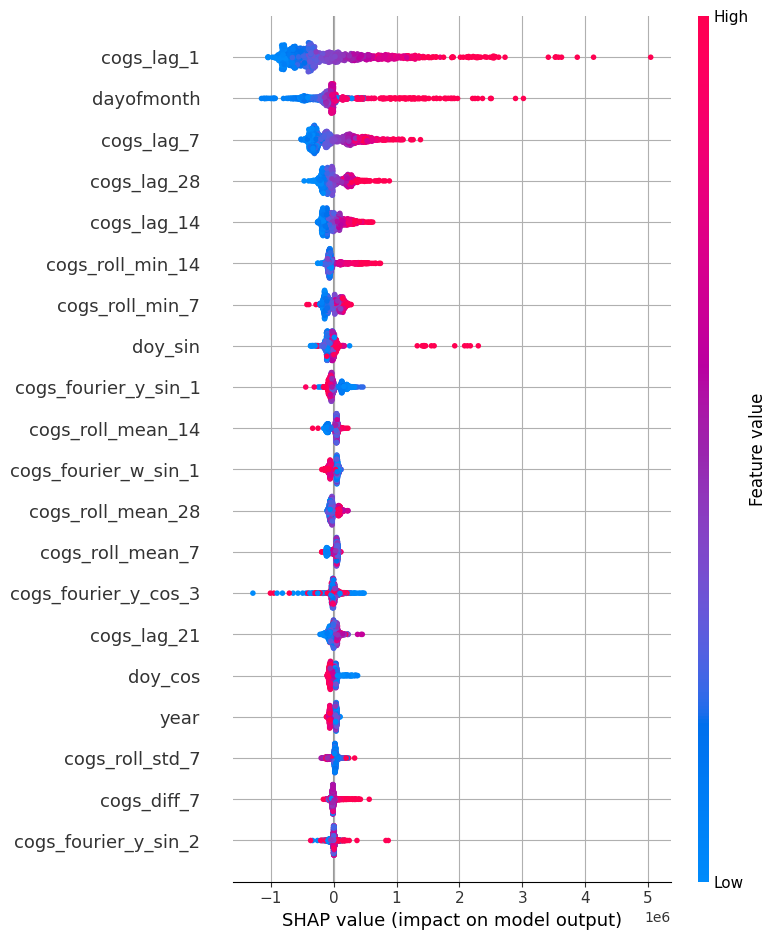

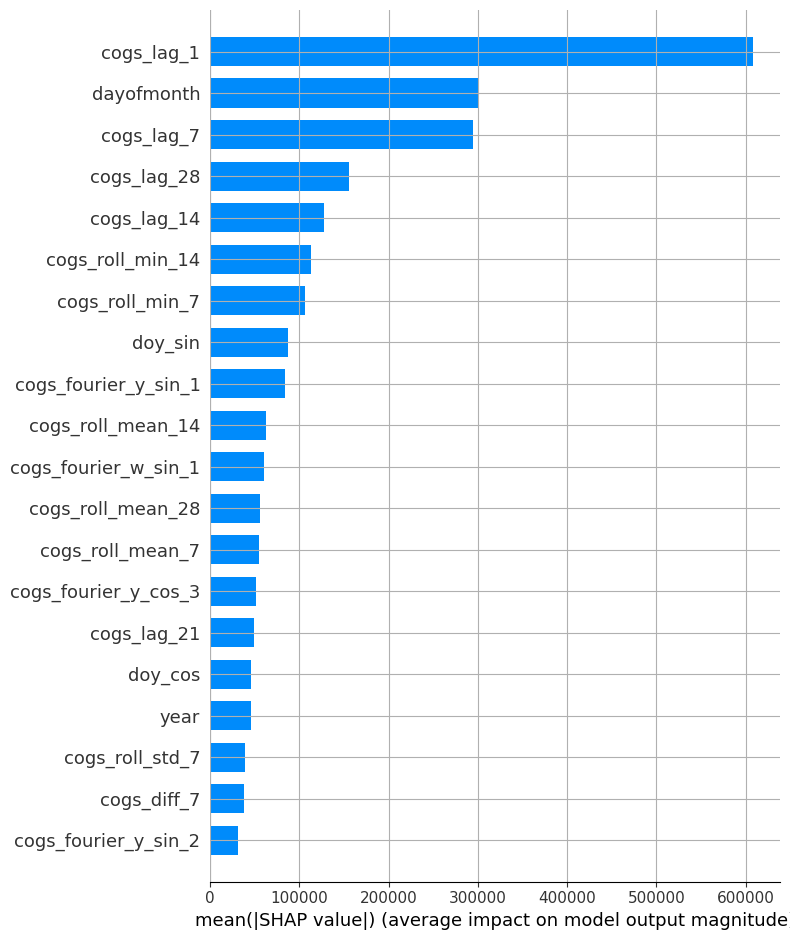

In [ ]:
# ============================================================
# Box 12R
# SHAP EXPLAINABILITY — BEST REVENUE & COGS MODELS
# Không cần chạy lại grid search
# Chỉ cần đã có final_revenue_model, final_cogs_model, df_rev, df_cogs
# ============================================================

# Nếu chưa cài shap trong môi trường
# !pip install shap -q

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1) Chuẩn bị feature cho Revenue
# ------------------------------------------------------------

revenue_ml = make_revenue_features(df_rev).dropna()

revenue_feature_cols = [
    c for c in revenue_ml.columns
    if c not in ["Revenue", "target"]
]

X_revenue = revenue_ml[revenue_feature_cols]

# Lấy sample để SHAP chạy nhanh hơn
X_revenue_sample = X_revenue.sample(
    n=min(1000, len(X_revenue)),
    random_state=42
)

# ------------------------------------------------------------
# 2) SHAP cho Revenue model
# ------------------------------------------------------------

revenue_explainer = shap.TreeExplainer(final_revenue_model)
revenue_shap_values = revenue_explainer.shap_values(X_revenue_sample)

# Summary plot dạng beeswarm
shap.summary_plot(
    revenue_shap_values,
    X_revenue_sample,
    plot_type="dot",
    show=True
)

# Summary plot dạng bar
shap.summary_plot(
    revenue_shap_values,
    X_revenue_sample,
    plot_type="bar",
    show=True
)


# ------------------------------------------------------------
# 3) Chuẩn bị feature cho COGS
# ------------------------------------------------------------

cogs_ml = make_cogs_features(df_cogs).dropna()

cogs_feature_cols = [
    c for c in cogs_ml.columns
    if c not in ["COGS", "target"]
]

X_cogs = cogs_ml[cogs_feature_cols]

# Lấy sample để SHAP chạy nhanh hơn
X_cogs_sample = X_cogs.sample(
    n=min(1000, len(X_cogs)),
    random_state=42
)

# ------------------------------------------------------------
# 4) SHAP cho COGS model
# ------------------------------------------------------------

cogs_explainer = shap.TreeExplainer(final_cogs_model)
cogs_shap_values = cogs_explainer.shap_values(X_cogs_sample)

# Summary plot dạng beeswarm
shap.summary_plot(
    cogs_shap_values,
    X_cogs_sample,
    plot_type="dot",
    show=True
)

# Summary plot dạng bar
shap.summary_plot(
    cogs_shap_values,
    X_cogs_sample,
    plot_type="bar",
    show=True
)

##2. COGS

###2.1. Configure

In [ ]:
# ============================================================
# BOX 1C — CONFIGURATION COGS
# ============================================================

# Các thư viện đã import ở phần Revenue nên box này chủ yếu setup riêng cho COGS

from sklearn.model_selection import ParameterGrid

# ----------------------------
# Grid tuning cho COGS
# ----------------------------
# Logic:
# - Không search quá rộng
# - Chỉ giữ các vùng parameter có tín hiệu tốt từ sample tuning
# - Mỗi model khoảng 32–64 tổ hợp để cân bằng giữa performance và thời gian chạy


# ============================================================
# XGBOOST PARAM GRID — COGS
# ============================================================


xgb_param_grid_cogs = {
    "n_estimators": [800, 1000],
    "learning_rate": [0.05, 0.06],
    "max_depth": [3, 4],
    "min_child_weight": [3, 10],
    "subsample": [1.00],
    "colsample_bytree": [0.67, 0.72],
    "reg_alpha": [0.56],
    "reg_lambda": [2.0, 4.5]
}


# ============================================================
# LIGHTGBM PARAM GRID — COGS
# ============================================================


lgbm_param_grid_cogs = {
    "n_estimators": [500, 600],
    "learning_rate": [0.06, 0.07],
    "num_leaves": [15, 31],
    "max_depth": [4, 5],
    "min_child_samples": [40, 50],
    "subsample": [0.50],
    "colsample_bytree": [0.94],
    "reg_alpha": [1.00],
    "reg_lambda": [1.5, 2.5]
}


# ============================================================
# CATBOOST PARAM GRID — COGS
# ============================================================


cat_param_grid_cogs = {
    "iterations": [900, 1000],
    "learning_rate": [0.06, 0.07],
    "depth": [5, 6],
    "l2_leaf_reg": [1, 3],
    "random_strength": [0.0, 0.56],
    "bagging_temperature": [0.0, 0.11]
}


# ============================================================
# CHECK SỐ LƯỢNG COMBINATIONS
# ============================================================

print("Number of COGS grid combinations:")

xgb_n_grid_cogs = len(list(ParameterGrid(xgb_param_grid_cogs)))
lgbm_n_grid_cogs = len(list(ParameterGrid(lgbm_param_grid_cogs)))
cat_n_grid_cogs = len(list(ParameterGrid(cat_param_grid_cogs)))

print(f"XGBoost COGS:  {xgb_n_grid_cogs} combinations")
print(f"LightGBM COGS: {lgbm_n_grid_cogs} combinations")
print(f"CatBoost COGS: {cat_n_grid_cogs} combinations")

Number of COGS grid combinations:
XGBoost COGS:  64 combinations
LightGBM COGS: 64 combinations
CatBoost COGS: 64 combinations


In [ ]:
# ============================================================
# BOX 2C — PREPARE COGS DATA
# ============================================================

df_cogs = df_sales.copy()

df_cogs["Date"] = pd.to_datetime(df_cogs["Date"])
df_cogs = df_cogs.sort_values("Date").reset_index(drop=True)

df_cogs = df_cogs[["Date", "COGS"]].copy()

# Tạo daily index liên tục
full_dates_cogs = pd.date_range(df_cogs["Date"].min(), df_cogs["Date"].max(), freq="D")

df_cogs = (
    df_cogs.set_index("Date")
           .reindex(full_dates_cogs)
           .rename_axis("Date")
           .reset_index()
)

# Ngày thiếu dữ liệu được hiểu là không phát sinh COGS
df_cogs["COGS"] = df_cogs["COGS"].fillna(0)

df_cogs = df_cogs[
    (df_cogs["Date"] >= train_start) &
    (df_cogs["Date"] <= train_end)
].copy()

df_cogs = df_cogs.set_index("Date").sort_index()

print("COGS daily data shape:", df_cogs.shape)
print("COGS train range:", df_cogs.index.min(), "to", df_cogs.index.max())
display(df_cogs.head())

COGS daily data shape: (3833, 1)
COGS train range: 2012-07-04 00:00:00 to 2022-12-31 00:00:00


,COGS
Date,
2012-07-04,3982991.19
2012-07-05,2150580.23
2012-07-06,2517632.84
2012-07-07,2108246.62
2012-07-08,1808622.79


In [ ]:
# ============================================================
# BOX 3C — VALIDATION COGS
# ============================================================

def tune_cogs_model_with_walking(model_name, model_class, param_grid, fixed_params):
    """
    Tuning model cho COGS bằng walking validation.
    Model tốt nhất được chọn theo mean RMSE.
    """

    daily_ml = make_cogs_features(df_cogs).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["COGS", "target"]
    ]

    splits = generate_walk_splits(
        index=daily_ml.index,
        initial_train_end=initial_train_end,
        val_horizon_days=val_horizon_days,
        step_days=step_days,
        final_date=train_end
    )

    print(f"\nTuning {model_name} for COGS")
    print(f"Number of walking folds: {len(splits)}")

    keys = list(param_grid.keys())
    values = list(param_grid.values())
    all_combinations = list(itertools.product(*values))

    print(f"Total parameter combinations: {len(all_combinations)}")

    results = []
    best_score = np.inf
    best_params = None

    for i, combo in enumerate(all_combinations, 1):
        params = dict(zip(keys, combo))

        fold_rmse = []
        fold_mae = []
        fold_rmspe = []
        fold_mape = []

        for tr_end, va_start, va_end in splits:
            train_df = daily_ml[daily_ml.index <= tr_end].copy()
            val_df = daily_ml[
                (daily_ml.index >= va_start) &
                (daily_ml.index <= va_end)
            ].copy()

            X_train = train_df[feature_cols]
            y_train = train_df["target"]

            X_val = val_df[feature_cols]
            y_val = val_df["target"]

            model = model_class(**fixed_params, **params)
            model.fit(X_train, y_train)

            pred_val = model.predict(X_val)
            pred_val = np.clip(pred_val, 0, None)

            metrics = evaluate_prediction(y_val, pred_val)

            fold_rmse.append(metrics["RMSE"])
            fold_mae.append(metrics["MAE"])
            fold_rmspe.append(metrics["RMSPE"])
            fold_mape.append(metrics["MAPE"])

        row = {
            "model": model_name,
            "target": "COGS",
            "params": params,
            "mean_rmse": np.mean(fold_rmse),
            "mean_mae": np.mean(fold_mae),
            "mean_rmspe": np.nanmean(fold_rmspe),
            "mean_mape": np.nanmean(fold_mape)
        }

        results.append(row)

        if row["mean_rmse"] < best_score:
            best_score = row["mean_rmse"]
            best_params = params

        if i % 5 == 0 or i == len(all_combinations):
            print(f"Done {i}/{len(all_combinations)}")

    results_df = pd.DataFrame(results).sort_values("mean_rmse").reset_index(drop=True)

    print(f"\nBest params for {model_name} - COGS:")
    print(best_params)
    print(f"Best mean RMSE: {best_score:,.2f}")

    return best_params, results_df, feature_cols

###2.2. STL Analysis

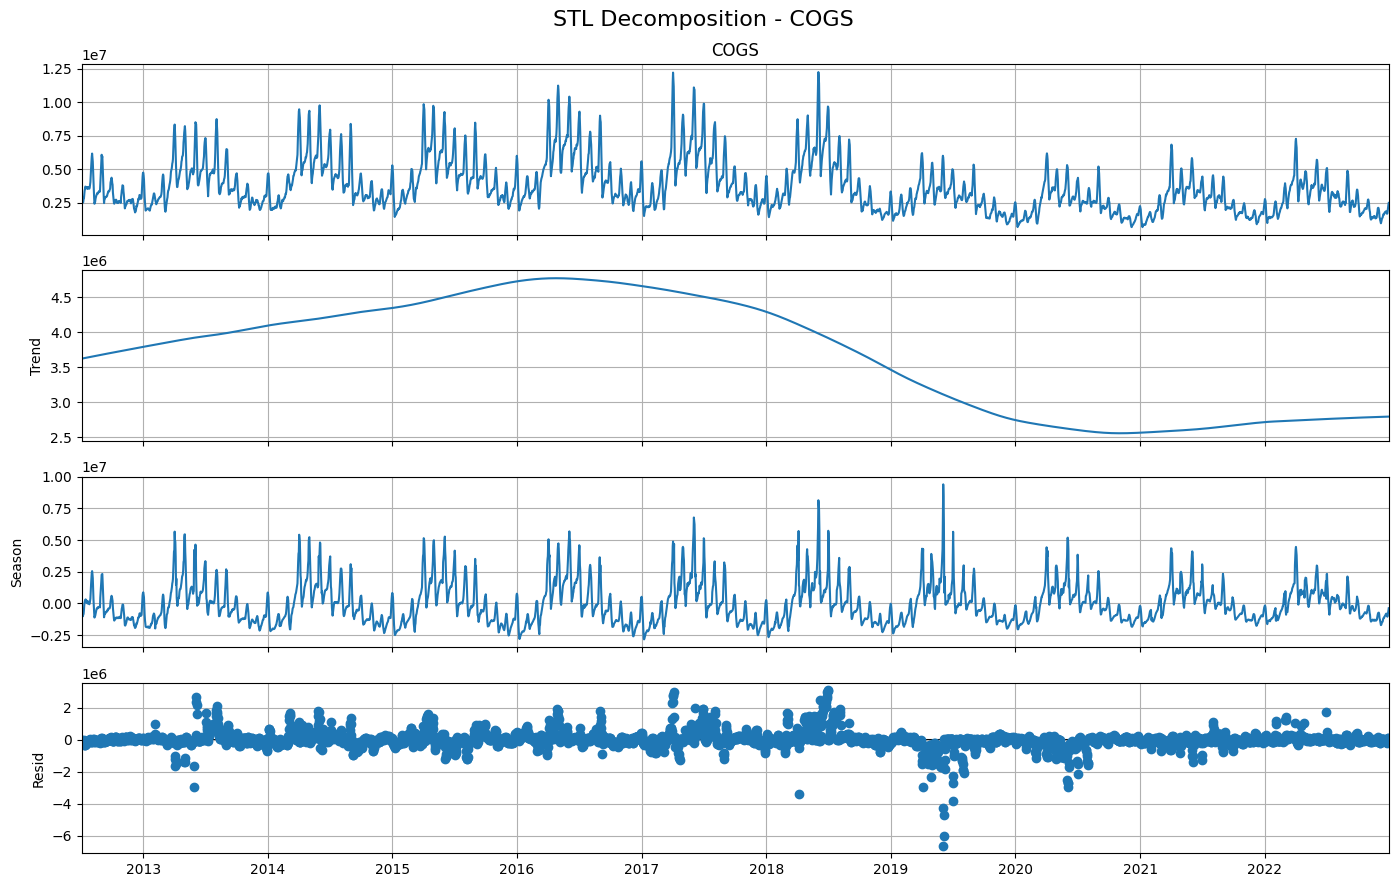

In [ ]:
# ============================================================
# BOX 4C — ĐÁNH GIÁ STL COGS
# ============================================================

def plot_stl_cogs(data, target_col="COGS", period=365):
    """
    Tách COGS thành trend, seasonal và residual.
    Mục tiêu là xem COGS có đi theo Revenue, có mùa vụ hay có nhiễu bất thường không.
    """

    series = data[target_col].copy()

    # Làm mượt 7 ngày để giảm nhiễu daily
    series = series.rolling(7, min_periods=1).mean()

    stl = STL(series, period=period, robust=True)
    result = stl.fit()

    fig = result.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle("STL Decomposition - COGS", fontsize=16)
    plt.tight_layout()
    plt.show()

    return result


stl_cogs = plot_stl_cogs(df_cogs)

COGS train shape: (3412, 54)
COGS test shape : (365, 54)

Running XGBoost sensitivity for COGS: n_estimators
Done: n_estimators

Running XGBoost sensitivity for COGS: learning_rate
Done: learning_rate

Running XGBoost sensitivity for COGS: max_depth
Done: max_depth

Running XGBoost sensitivity for COGS: min_child_weight
Done: min_child_weight

Running XGBoost sensitivity for COGS: subsample
Done: subsample

Running XGBoost sensitivity for COGS: colsample_bytree
Done: colsample_bytree

Running XGBoost sensitivity for COGS: reg_alpha
Done: reg_alpha

Running XGBoost sensitivity for COGS: reg_lambda
Done: reg_lambda

Running LightGBM sensitivity for COGS: n_estimators
Done: n_estimators

Running LightGBM sensitivity for COGS: learning_rate
Done: learning_rate

Running LightGBM sensitivity for COGS: num_leaves
Done: num_leaves

Running LightGBM sensitivity for COGS: max_depth
Done: max_depth

Running LightGBM sensitivity for COGS: min_child_samples
Done: min_child_samples

Running LightGBM

,model,target,parameter,value,RMSE,MAE,RMSPE,MAPE
0,XGBoost,COGS,n_estimators,100.0,661827.201525,481736.541486,32.706747,21.103169
1,XGBoost,COGS,n_estimators,200.0,640671.644245,476959.167438,30.162566,20.344117
2,XGBoost,COGS,n_estimators,300.0,632237.339554,476656.586795,29.617431,20.210933
3,XGBoost,COGS,n_estimators,400.0,626167.790892,473736.193685,29.107163,19.993192
4,XGBoost,COGS,n_estimators,500.0,625405.444303,473044.372596,29.062177,19.923703


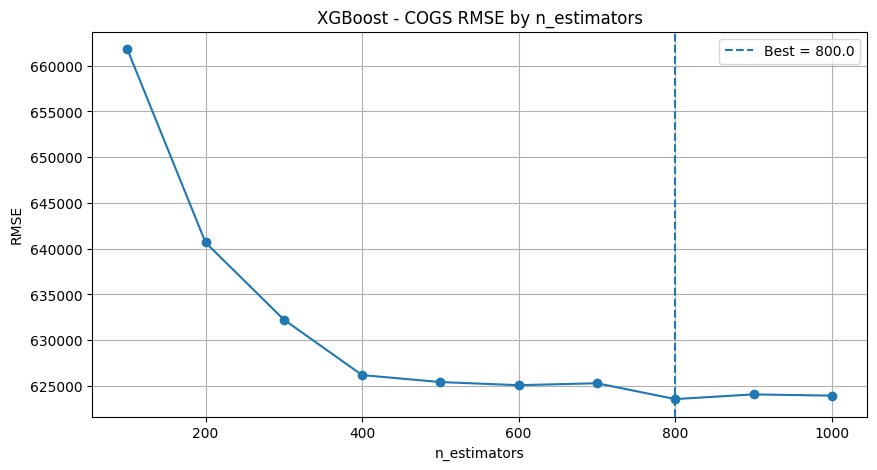

XGBoost | COGS | n_estimators | Best value: 800.0 | Best RMSE: 623,543.33


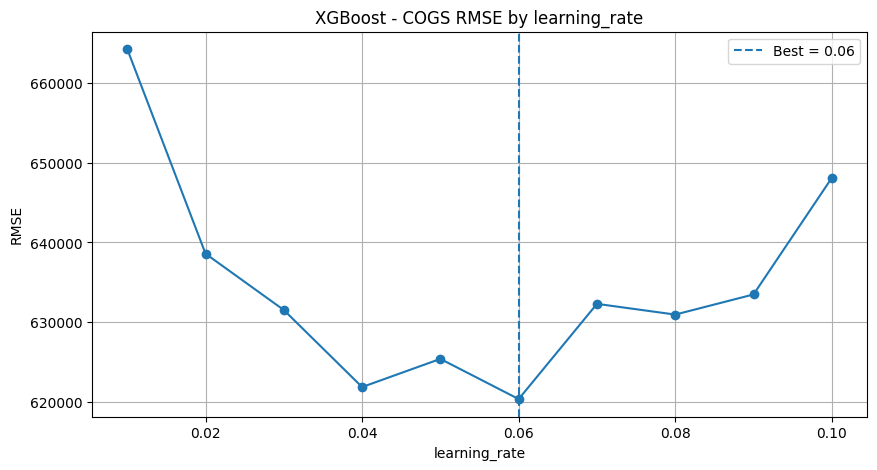

XGBoost | COGS | learning_rate | Best value: 0.06 | Best RMSE: 620,372.57


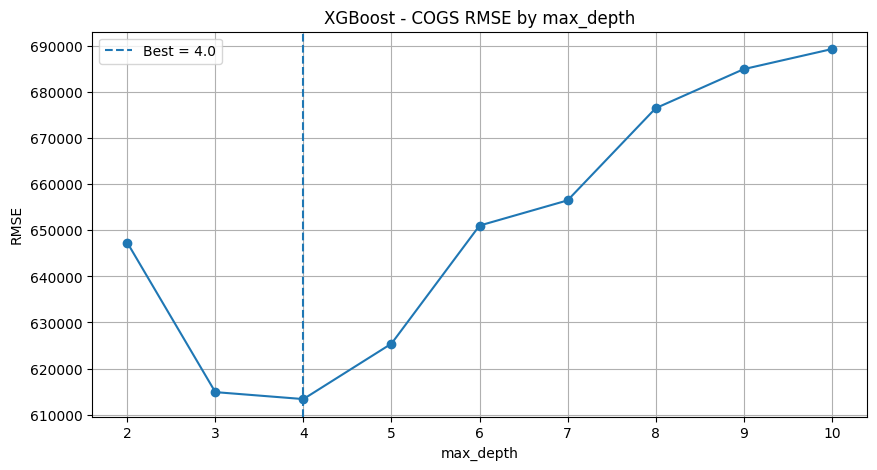

XGBoost | COGS | max_depth | Best value: 4.0 | Best RMSE: 613,385.61


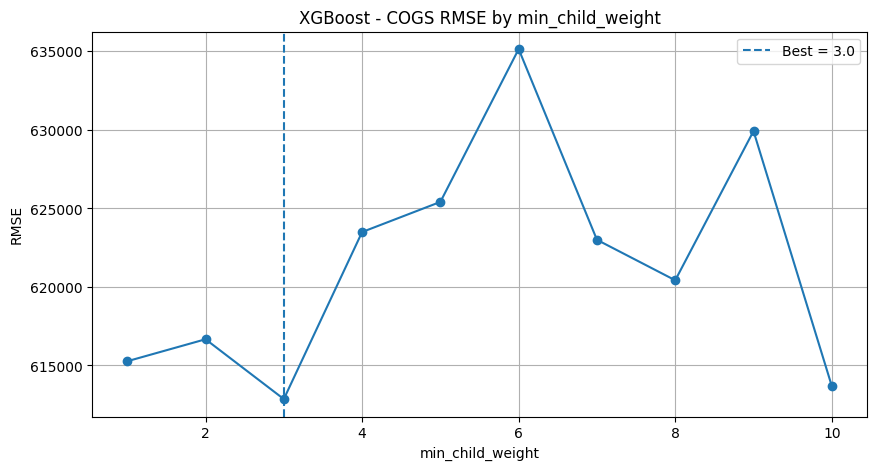

XGBoost | COGS | min_child_weight | Best value: 3.0 | Best RMSE: 612,855.53


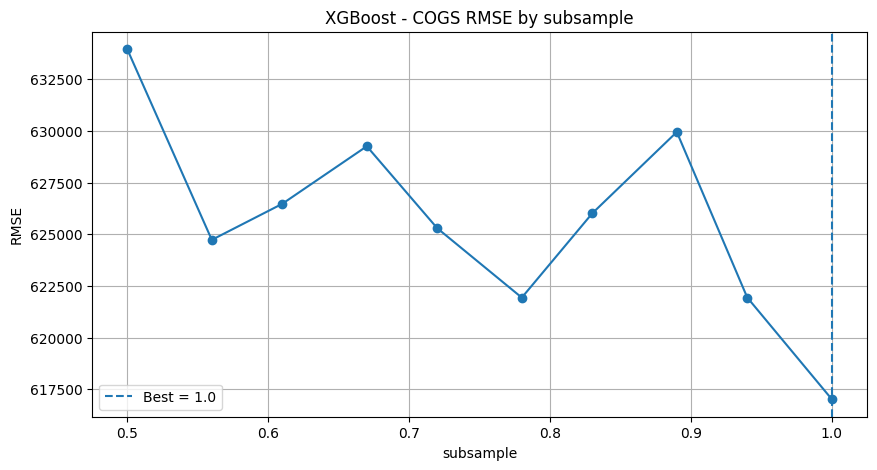

XGBoost | COGS | subsample | Best value: 1.0 | Best RMSE: 617,016.84


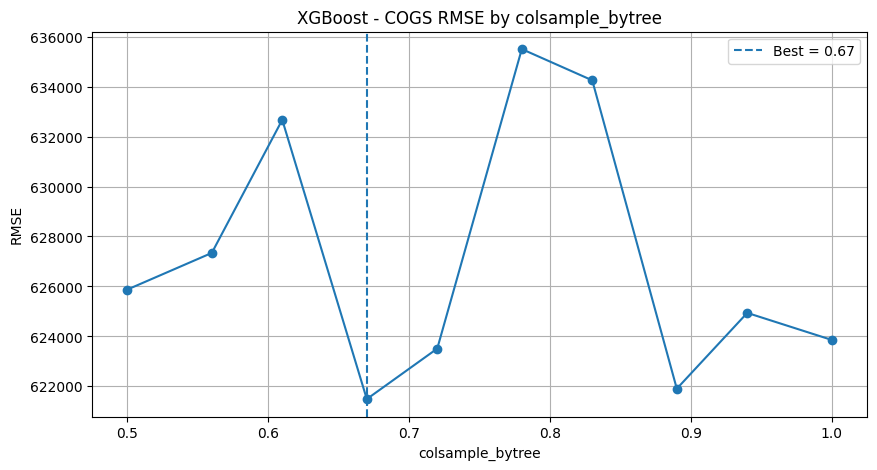

XGBoost | COGS | colsample_bytree | Best value: 0.67 | Best RMSE: 621,482.25


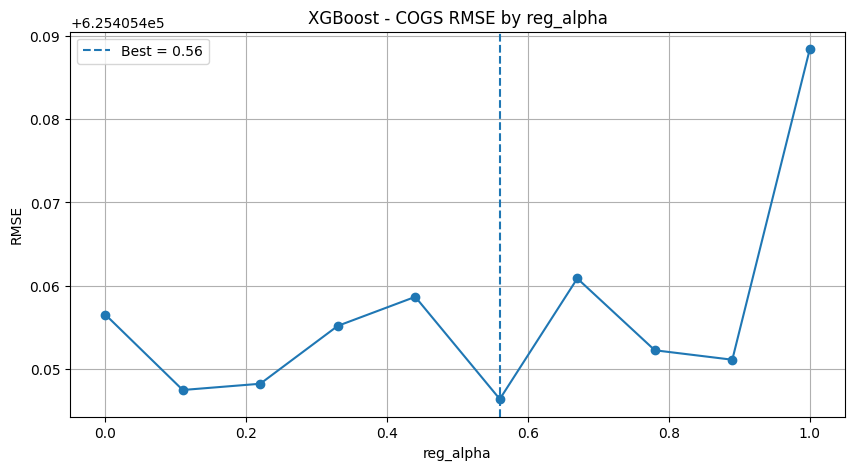

XGBoost | COGS | reg_alpha | Best value: 0.56 | Best RMSE: 625,405.45


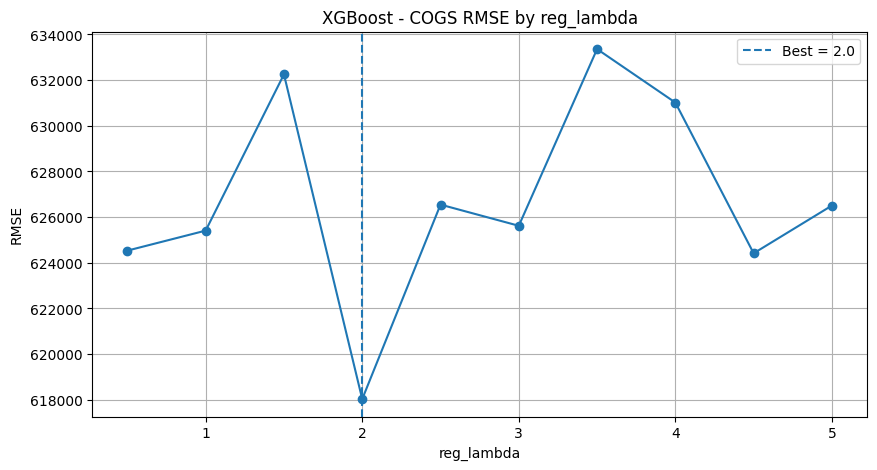

XGBoost | COGS | reg_lambda | Best value: 2.0 | Best RMSE: 618,023.70


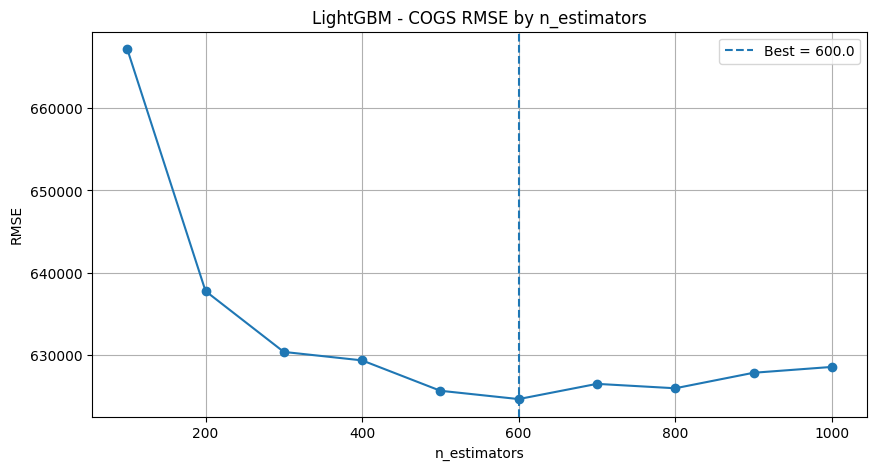

LightGBM | COGS | n_estimators | Best value: 600.0 | Best RMSE: 624,678.33


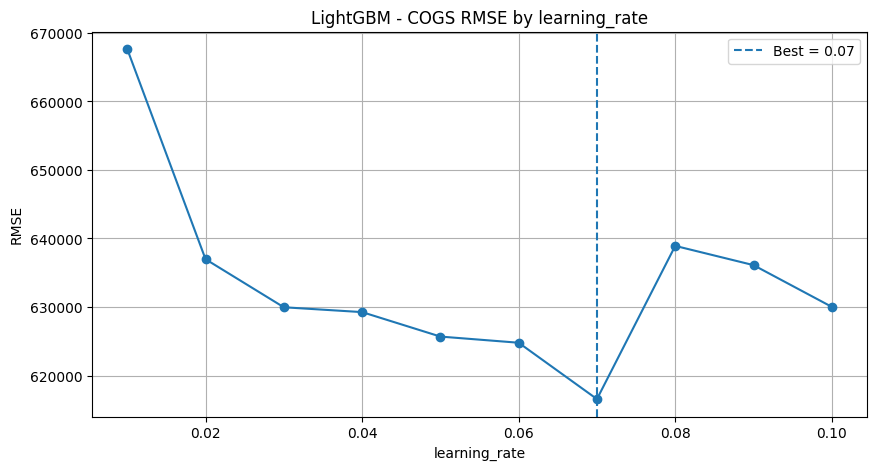

LightGBM | COGS | learning_rate | Best value: 0.07 | Best RMSE: 616,572.20


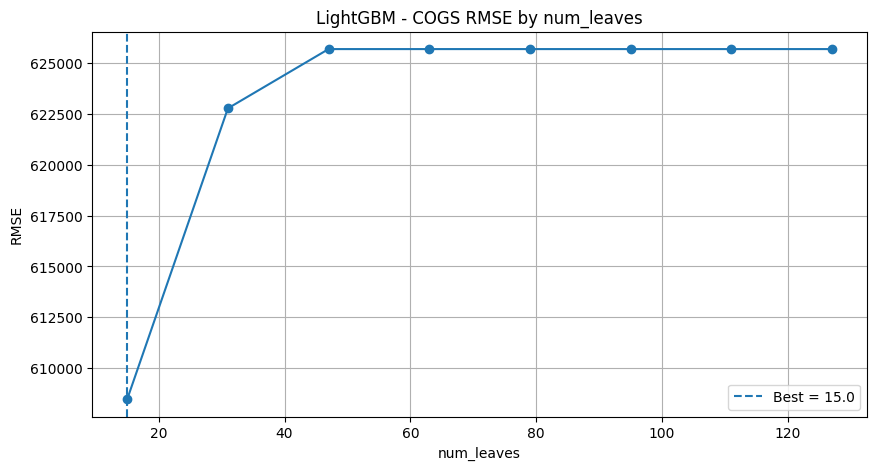

LightGBM | COGS | num_leaves | Best value: 15.0 | Best RMSE: 608,475.57


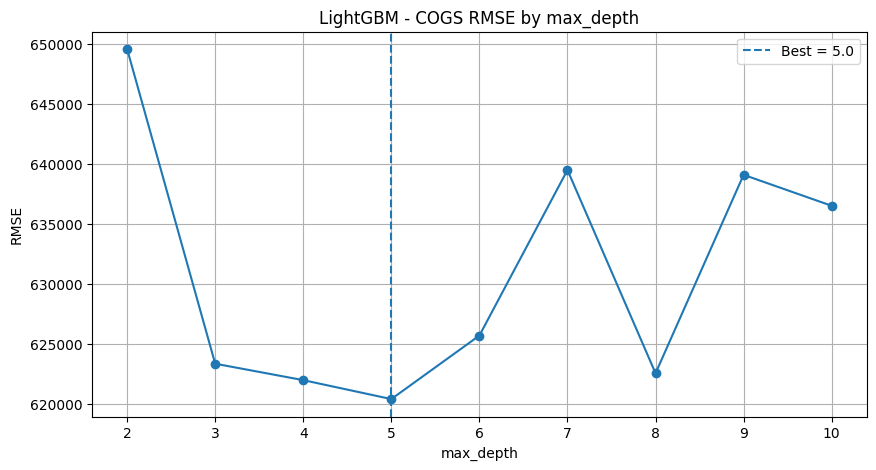

LightGBM | COGS | max_depth | Best value: 5.0 | Best RMSE: 620,389.03


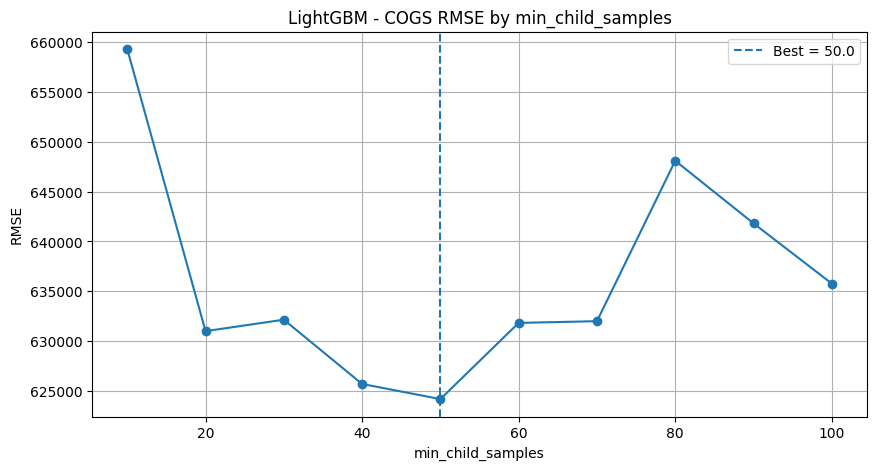

LightGBM | COGS | min_child_samples | Best value: 50.0 | Best RMSE: 624,170.70


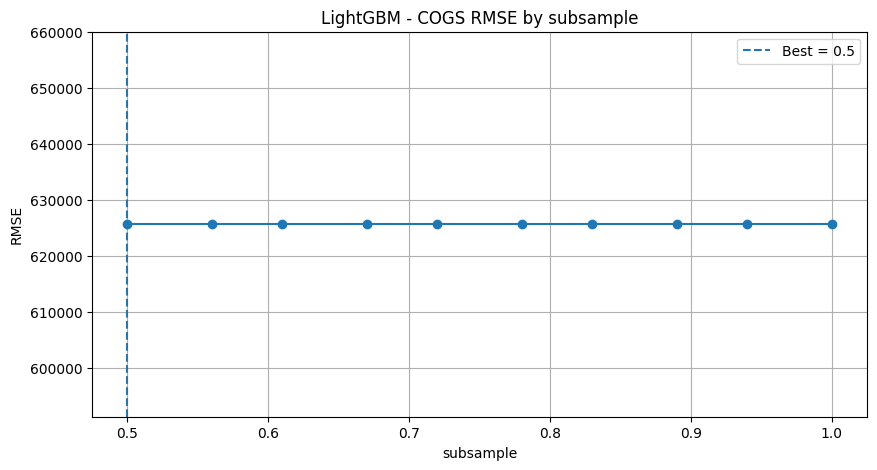

LightGBM | COGS | subsample | Best value: 0.5 | Best RMSE: 625,687.22


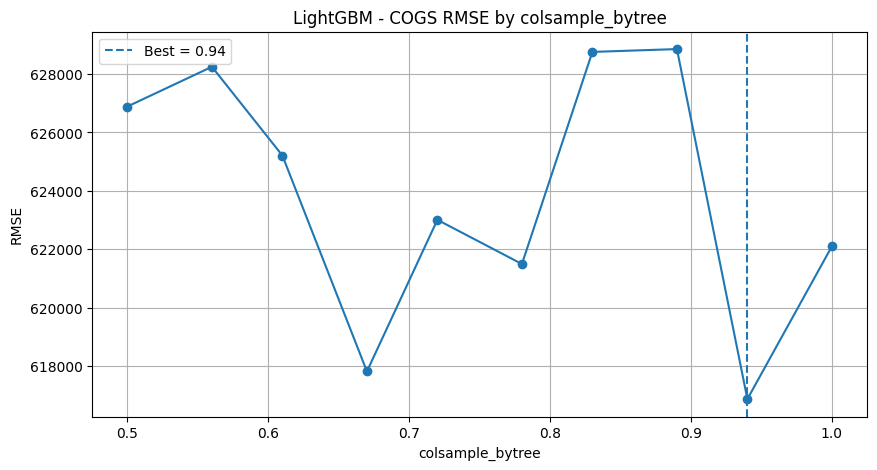

LightGBM | COGS | colsample_bytree | Best value: 0.94 | Best RMSE: 616,874.08


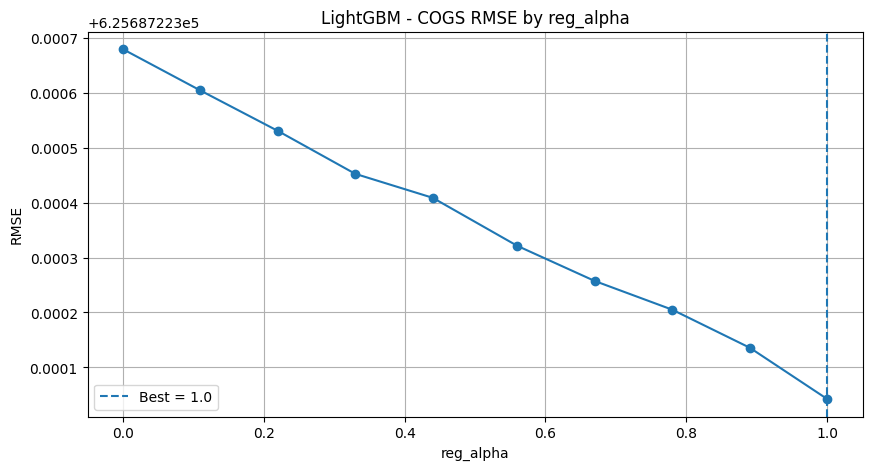

LightGBM | COGS | reg_alpha | Best value: 1.0 | Best RMSE: 625,687.22


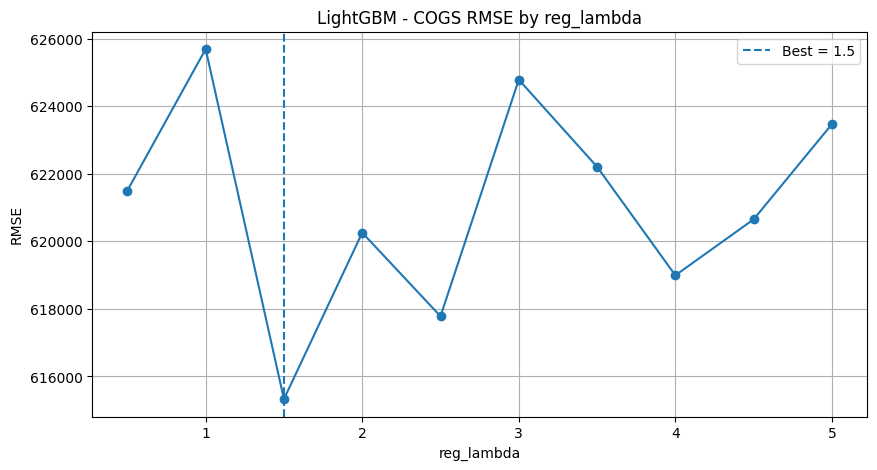

LightGBM | COGS | reg_lambda | Best value: 1.5 | Best RMSE: 615,325.45


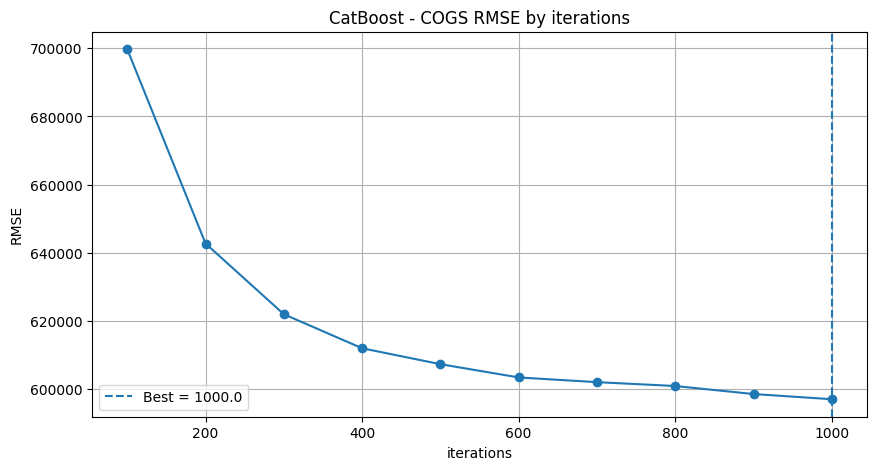

CatBoost | COGS | iterations | Best value: 1000.0 | Best RMSE: 596,984.76


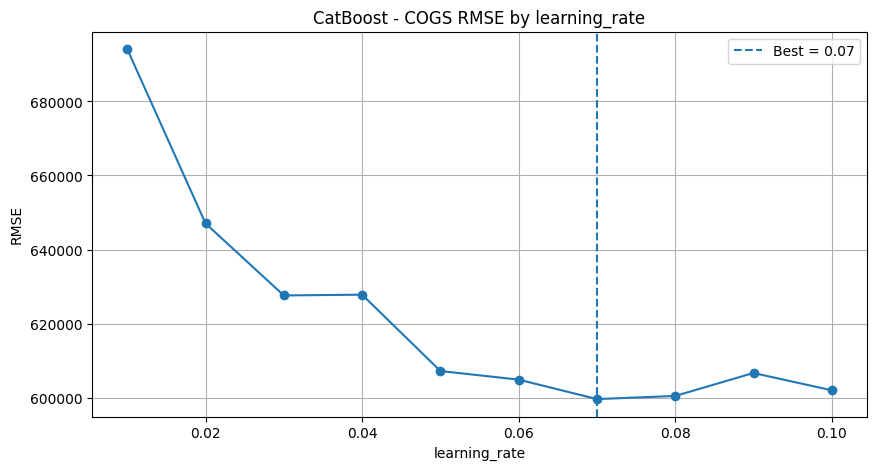

CatBoost | COGS | learning_rate | Best value: 0.07 | Best RMSE: 599,712.29


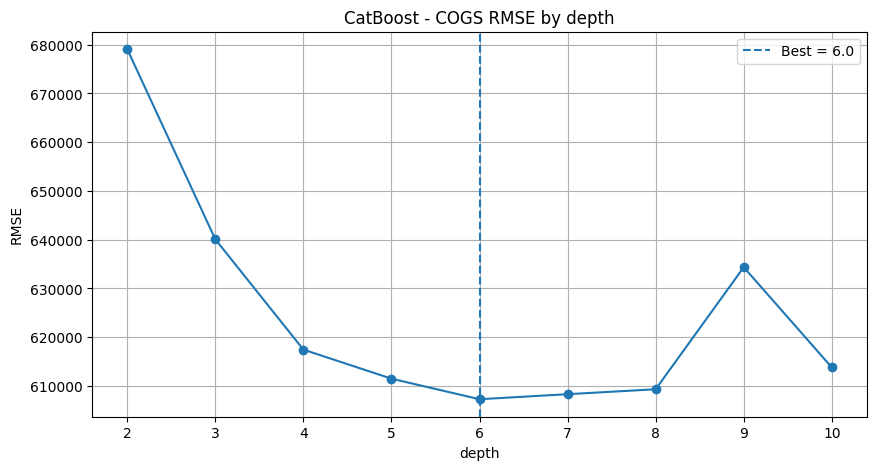

CatBoost | COGS | depth | Best value: 6.0 | Best RMSE: 607,277.74


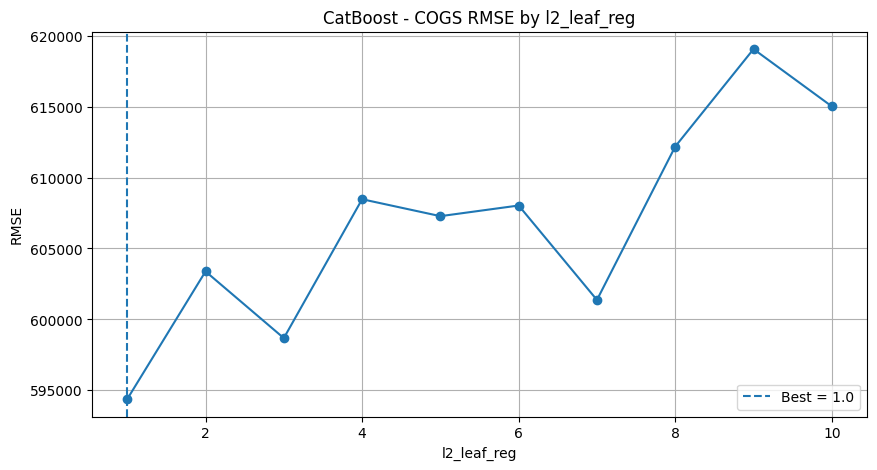

CatBoost | COGS | l2_leaf_reg | Best value: 1.0 | Best RMSE: 594,367.97


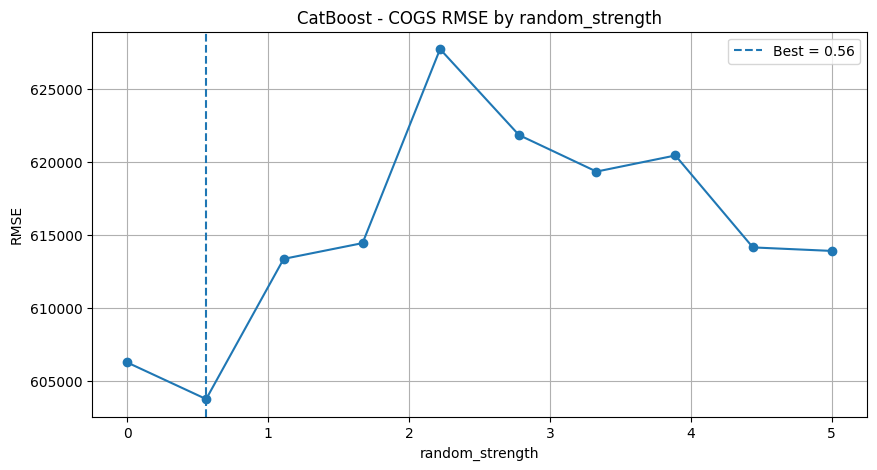

CatBoost | COGS | random_strength | Best value: 0.56 | Best RMSE: 603,767.80


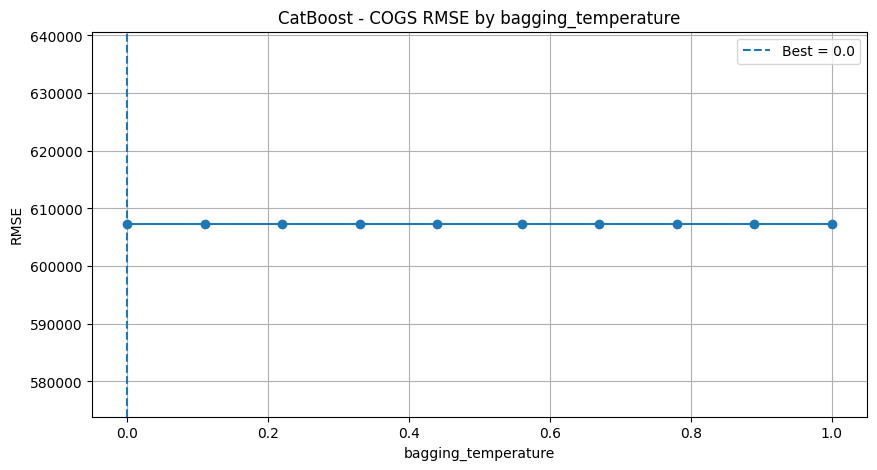

CatBoost | COGS | bagging_temperature | Best value: 0.0 | Best RMSE: 607,277.74


,model,parameter,target,value,RMSE,MAE,RMSPE,MAPE
3,CatBoost,l2_leaf_reg,COGS,1.00,594367.966799,444767.857016,27.436351,18.945912
2,CatBoost,iterations,COGS,1000.00,596984.761997,454439.185687,27.519888,19.097046
4,CatBoost,learning_rate,COGS,0.07,599712.287485,451821.770919,28.096528,19.226606
5,CatBoost,random_strength,COGS,0.56,603767.796267,449583.284399,27.590993,18.902630
0,CatBoost,bagging_temperature,COGS,0.11,607277.742753,455847.577953,28.271556,19.264022
1,CatBoost,depth,COGS,6.00,607277.742753,455847.577953,28.271556,19.264022
11,LightGBM,num_leaves,COGS,15.00,608475.569509,459721.550474,28.104983,19.617034
13,LightGBM,reg_lambda,COGS,1.50,615325.451982,460741.812905,28.519770,19.527473
7,LightGBM,learning_rate,COGS,0.07,616572.202454,468454.347414,28.954352,19.991424
6,LightGBM,colsample_bytree,COGS,0.94,616874.081287,467201.518883,29.835308,20.122853


,model,target,parameter,suggested_values,best_value,best_rmse
0,CatBoost,COGS,bagging_temperature,"[0.0, 0.11, 0.22]",0.00,607277.742753
1,CatBoost,COGS,depth,"[6.0, 7.0, 8.0]",6.00,607277.742753
2,CatBoost,COGS,iterations,"[1000.0, 900.0, 800.0]",1000.00,596984.761997
3,CatBoost,COGS,l2_leaf_reg,"[1.0, 3.0, 7.0]",1.00,594367.966799
4,CatBoost,COGS,learning_rate,"[0.07, 0.08, 0.1]",0.07,599712.287485
5,CatBoost,COGS,random_strength,"[0.56, 0.0, 1.11]",0.56,603767.796267
6,LightGBM,COGS,colsample_bytree,"[0.94, 0.67, 0.78]",0.94,616874.081287
7,LightGBM,COGS,learning_rate,"[0.07, 0.06, 0.05]",0.07,616572.202454
8,LightGBM,COGS,max_depth,"[5.0, 4.0, 8.0]",5.00,620389.026426
9,LightGBM,COGS,min_child_samples,"[50.0, 40.0, 20.0]",50.00,624170.701354


In [ ]:
# ============================================================
# BOX 5C - PARAMETER SENSITIVITY ANALYSIS — COGS
# Mục tiêu:
# - Mỗi lần chỉ thay đổi 1 hyperparameter
# - Các hyperparameter còn lại giữ baseline
# - Đo RMSE trên holdout 2022
# - Vẽ biểu đồ đường để hiểu khoảng tham số nào quá xấu
# - Chỉ dùng để hỗ trợ thu hẹp grid search, không dùng để chọn final params
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


# ============================================================
# 1) CHUẨN BỊ DATA COGS CHO HOLDOUT 2022
# ============================================================

def prepare_cogs_holdout(df_cogs, split_date="2022-01-01"):
    """
    Tạo tập train/test cho COGS:
    - Train: trước năm 2022
    - Test: năm 2022
    """

    daily_ml = make_cogs_features(df_cogs).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["COGS", "target"]
    ]

    train_df = daily_ml[daily_ml.index < split_date].copy()
    test_df  = daily_ml[daily_ml.index >= split_date].copy()

    X_train = train_df[feature_cols]
    y_train = train_df["target"]

    X_test = test_df[feature_cols]
    y_test = test_df["target"]

    return X_train, y_train, X_test, y_test, feature_cols


X_train_cogs, y_train_cogs, X_test_cogs, y_test_cogs, cogs_feature_cols = prepare_cogs_holdout(df_cogs)

print("COGS train shape:", X_train_cogs.shape)
print("COGS test shape :", X_test_cogs.shape)


# ============================================================
# 2) METRIC
# ============================================================

def safe_mape(y_true, y_pred):
    """
    MAPE bỏ qua actual = 0 để tránh lỗi chia cho 0.
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


def safe_rmspe(y_true, y_pred):
    """
    RMSPE dùng như chỉ số phụ để quan sát sai số tương đối.
    """

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    if mask.sum() == 0:
        return np.nan

    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2)) * 100


def evaluate_cogs_pred(y_true, y_pred):
    """
    Chỉ số chính: RMSE, MAE
    Chỉ số phụ: RMSPE, MAPE
    """

    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSPE": safe_rmspe(y_true, y_pred),
        "MAPE": safe_mape(y_true, y_pred)
    }


# ============================================================
# 3) BASELINE PARAMS CHO TỪNG MODEL
# ============================================================

xgb_base_params_cogs = {
    "objective": "reg:squarederror",
    "random_state": 42,
    "tree_method": "hist",
    "verbosity": 0,
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 5,
    "min_child_weight": 5,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0
}

lgbm_base_params_cogs = {
    "objective": "regression",
    "random_state": 42,
    "verbose": -1,
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "max_depth": 6,
    "min_child_samples": 40,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0
}

cat_base_params_cogs = {
    "loss_function": "RMSE",
    "random_seed": 42,
    "verbose": False,
    "iterations": 500,
    "learning_rate": 0.05,
    "depth": 6,
    "l2_leaf_reg": 5,
    "random_strength": 1,
    "bagging_temperature": 0.5
}


# ============================================================
# 4) PARAMETER RANGE ĐỂ TEST
# Mỗi tham số chạy khoảng 8-10 giá trị
# ============================================================

xgb_param_ranges_cogs = {
    "n_estimators": list(range(100, 1100, 100)),
    "learning_rate": np.round(np.linspace(0.01, 0.10, 10), 3).tolist(),
    "max_depth": list(range(2, 11)),
    "min_child_weight": list(range(1, 11)),
    "subsample": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "colsample_bytree": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "reg_alpha": np.round(np.linspace(0.0, 1.0, 10), 2).tolist(),
    "reg_lambda": np.round(np.linspace(0.5, 5.0, 10), 2).tolist()
}

lgbm_param_ranges_cogs = {
    "n_estimators": list(range(100, 1100, 100)),
    "learning_rate": np.round(np.linspace(0.01, 0.10, 10), 3).tolist(),
    "num_leaves": [15, 31, 47, 63, 79, 95, 111, 127],
    "max_depth": list(range(2, 11)),
    "min_child_samples": [10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    "subsample": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "colsample_bytree": np.round(np.linspace(0.5, 1.0, 10), 2).tolist(),
    "reg_alpha": np.round(np.linspace(0.0, 1.0, 10), 2).tolist(),
    "reg_lambda": np.round(np.linspace(0.5, 5.0, 10), 2).tolist()
}

cat_param_ranges_cogs = {
    "iterations": list(range(100, 1100, 100)),
    "learning_rate": np.round(np.linspace(0.01, 0.10, 10), 3).tolist(),
    "depth": list(range(2, 11)),
    "l2_leaf_reg": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "random_strength": np.round(np.linspace(0.0, 5.0, 10), 2).tolist(),
    "bagging_temperature": np.round(np.linspace(0.0, 1.0, 10), 2).tolist()
}


# ============================================================
# 5) HÀM CHẠY SENSITIVITY CHO 1 MODEL
# ============================================================

def run_param_sensitivity_cogs(
    model_name,
    model_class,
    base_params,
    param_ranges,
    X_train,
    y_train,
    X_test,
    y_test
):
    """
    Chạy sensitivity analysis cho từng hyperparameter.
    Mỗi lần chỉ thay đổi 1 tham số.
    """

    all_results = []

    for param_name, values in param_ranges.items():
        print(f"\nRunning {model_name} sensitivity for COGS: {param_name}")

        for value in values:
            params = base_params.copy()
            params[param_name] = value

            model = model_class(**params)
            model.fit(X_train, y_train)

            pred = model.predict(X_test)
            pred = np.clip(pred, 0, None)

            metrics = evaluate_cogs_pred(y_test, pred)

            all_results.append({
                "model": model_name,
                "target": "COGS",
                "parameter": param_name,
                "value": value,
                "RMSE": metrics["RMSE"],
                "MAE": metrics["MAE"],
                "RMSPE": metrics["RMSPE"],
                "MAPE": metrics["MAPE"]
            })

        print(f"Done: {param_name}")

    results_df = pd.DataFrame(all_results)

    return results_df


# ============================================================
# 6) CHẠY SENSITIVITY CHO 3 MODEL — COGS
# ============================================================

xgb_sensitivity_cogs = run_param_sensitivity_cogs(
    model_name="XGBoost",
    model_class=XGBRegressor,
    base_params=xgb_base_params_cogs,
    param_ranges=xgb_param_ranges_cogs,
    X_train=X_train_cogs,
    y_train=y_train_cogs,
    X_test=X_test_cogs,
    y_test=y_test_cogs
)

lgbm_sensitivity_cogs = run_param_sensitivity_cogs(
    model_name="LightGBM",
    model_class=LGBMRegressor,
    base_params=lgbm_base_params_cogs,
    param_ranges=lgbm_param_ranges_cogs,
    X_train=X_train_cogs,
    y_train=y_train_cogs,
    X_test=X_test_cogs,
    y_test=y_test_cogs
)

cat_sensitivity_cogs = run_param_sensitivity_cogs(
    model_name="CatBoost",
    model_class=CatBoostRegressor,
    base_params=cat_base_params_cogs,
    param_ranges=cat_param_ranges_cogs,
    X_train=X_train_cogs,
    y_train=y_train_cogs,
    X_test=X_test_cogs,
    y_test=y_test_cogs
)


# ============================================================
# 7) GỘP KẾT QUẢ
# ============================================================

cogs_sensitivity_results = pd.concat(
    [
        xgb_sensitivity_cogs,
        lgbm_sensitivity_cogs,
        cat_sensitivity_cogs
    ],
    axis=0
).reset_index(drop=True)

display(cogs_sensitivity_results.head())


# ============================================================
# 8) VẼ BIỂU ĐỒ RMSE THEO TỪNG PARAMETER
# ============================================================

def plot_param_sensitivity_cogs(results_df, model_name):
    """
    Vẽ từng biểu đồ riêng cho từng tham số.
    Trục X: giá trị tham số
    Trục Y: RMSE
    """

    model_df = results_df[results_df["model"] == model_name].copy()

    for param_name in model_df["parameter"].unique():
        temp = model_df[model_df["parameter"] == param_name].copy()
        temp = temp.sort_values("value")

        best_row = temp.loc[temp["RMSE"].idxmin()]

        plt.figure(figsize=(10, 5))
        plt.plot(temp["value"], temp["RMSE"], marker="o")
        plt.axvline(best_row["value"], linestyle="--", label=f"Best = {best_row['value']}")
        plt.title(f"{model_name} - COGS RMSE by {param_name}")
        plt.xlabel(param_name)
        plt.ylabel("RMSE")
        plt.legend()
        plt.grid(True)
        plt.show()

        print(
            f"{model_name} | COGS | {param_name} | "
            f"Best value: {best_row['value']} | "
            f"Best RMSE: {best_row['RMSE']:,.2f}"
        )


plot_param_sensitivity_cogs(cogs_sensitivity_results, "XGBoost")
plot_param_sensitivity_cogs(cogs_sensitivity_results, "LightGBM")
plot_param_sensitivity_cogs(cogs_sensitivity_results, "CatBoost")


# ============================================================
# 9) BẢNG BEST VALUE CHO MỖI PARAMETER
# ============================================================

best_param_summary_cogs = (
    cogs_sensitivity_results
    .sort_values("RMSE")
    .groupby(["model", "parameter"], as_index=False)
    .first()
    .sort_values(["model", "RMSE"])
)

display(best_param_summary_cogs)


# ============================================================
# 10) GỢI Ý GRID SEARCH HẸP TỪ SENSITIVITY
# ============================================================

def suggest_grid_from_sensitivity_cogs(results_df, top_k=3):
    """
    Gợi ý vùng grid search hẹp:
    - Lấy top_k giá trị có RMSE thấp nhất cho mỗi parameter
    - Dùng bảng này để giải thích vì sao chọn grid chính thức
    """

    suggested_rows = []

    for (model, param), group in results_df.groupby(["model", "parameter"]):
        temp = group.sort_values("RMSE").head(top_k)

        suggested_rows.append({
            "model": model,
            "target": "COGS",
            "parameter": param,
            "suggested_values": list(temp["value"]),
            "best_value": temp.iloc[0]["value"],
            "best_rmse": temp.iloc[0]["RMSE"]
        })

    suggested_df = pd.DataFrame(suggested_rows)

    return suggested_df.sort_values(["model", "parameter"]).reset_index(drop=True)


suggested_grid_cogs = suggest_grid_from_sensitivity_cogs(cogs_sensitivity_results, top_k=3)

display(suggested_grid_cogs)

###2.3. Feature Engineering

In [ ]:
# ============================================================
# BOX 6C — FEATURE ENGINEERING COGS
# ============================================================

def make_cogs_features(data):
    """
    Tạo feature riêng cho COGS.
    Feature gồm calendar, cyclic, lag, rolling, momentum và Fourier.
    """

    data = data.copy().sort_index()
    target_col = "COGS"

    # Calendar features
    data["dow"] = data.index.dayofweek
    data["weekofyear"] = data.index.isocalendar().week.astype(int)
    data["month"] = data.index.month
    data["quarter"] = data.index.quarter
    data["dayofmonth"] = data.index.day
    data["dayofyear"] = data.index.dayofyear
    data["year"] = data.index.year

    data["is_weekend"] = (data["dow"] >= 5).astype(int)
    data["is_month_start"] = data.index.is_month_start.astype(int)
    data["is_month_end"] = data.index.is_month_end.astype(int)
    data["is_quarter_start"] = data.index.is_quarter_start.astype(int)
    data["is_quarter_end"] = data.index.is_quarter_end.astype(int)

    # Cyclical features
    data["dow_sin"] = np.sin(2 * np.pi * data["dow"] / 7)
    data["dow_cos"] = np.cos(2 * np.pi * data["dow"] / 7)

    data["month_sin"] = np.sin(2 * np.pi * data["month"] / 12)
    data["month_cos"] = np.cos(2 * np.pi * data["month"] / 12)

    data["doy_sin"] = np.sin(2 * np.pi * data["dayofyear"] / 365.25)
    data["doy_cos"] = np.cos(2 * np.pi * data["dayofyear"] / 365.25)

    # Lag features
    for lag in [1, 2, 3, 7, 14, 21, 28]:
        data[f"cogs_lag_{lag}"] = data[target_col].shift(lag)

    # Rolling features
    for w in [7, 14, 28, 56]:
        data[f"cogs_roll_mean_{w}"] = data[target_col].shift(1).rolling(w).mean()
        data[f"cogs_roll_std_{w}"]  = data[target_col].shift(1).rolling(w).std()
        data[f"cogs_roll_min_{w}"]  = data[target_col].shift(1).rolling(w).min()
        data[f"cogs_roll_max_{w}"]  = data[target_col].shift(1).rolling(w).max()

    # Momentum features
    data["cogs_diff_1"]  = data[target_col].shift(1) - data[target_col].shift(2)
    data["cogs_diff_7"]  = data[target_col].shift(1) - data[target_col].shift(8)
    data["cogs_ratio_7"] = data[target_col].shift(1) / (data[target_col].shift(8) + 1e-6)

    # Fourier features
    fourier_weekly = add_fourier_terms(data.index, 7, 2, "cogs_fourier_w")
    fourier_yearly = add_fourier_terms(data.index, 365.25, 3, "cogs_fourier_y")

    data = pd.concat([data, fourier_weekly, fourier_yearly], axis=1)

    data["target"] = data[target_col]

    return data

###2.4. Model Training

####XGBoost

In [ ]:
# ============================================================
# BOX 7C — TRAIN XGBOOST COGS
# ============================================================

xgb_fixed_params_cogs = {
    "objective": "reg:squarederror",
    "random_state": RANDOM_STATE,
    "tree_method": "hist",
    "verbosity": 0
}

xgb_best_cogs, xgb_tuning_cogs, xgb_features_cogs = tune_cogs_model_with_walking(
    model_name="XGBoost",
    model_class=XGBRegressor,
    param_grid=xgb_param_grid_cogs,
    fixed_params=xgb_fixed_params_cogs
)

print("\nTop 5 XGBoost COGS tuning")
display(xgb_tuning_cogs.head())


Tuning XGBoost for COGS
Number of walking folds: 4
Total parameter combinations: 64
Done 5/64
Done 10/64
Done 15/64
Done 20/64
Done 25/64
Done 30/64
Done 35/64
Done 40/64
Done 45/64
Done 50/64
Done 55/64
Done 60/64
Done 64/64

Best params for XGBoost - COGS:
{'n_estimators': 1000, 'learning_rate': 0.06, 'max_depth': 3, 'min_child_weight': 10, 'subsample': 1.0, 'colsample_bytree': 0.72, 'reg_alpha': 0.56, 'reg_lambda': 4.5}
Best mean RMSE: 598,909.63

Top 5 XGBoost COGS tuning


,model,target,params,mean_rmse,mean_mae,mean_rmspe,mean_mape
0,XGBoost,COGS,"{'n_estimators': 1000, 'learning_rate': 0.06, ...",598909.630962,450209.796139,32.401393,21.248152
1,XGBoost,COGS,"{'n_estimators': 800, 'learning_rate': 0.06, '...",599912.017462,449919.215340,32.545913,21.290529
2,XGBoost,COGS,"{'n_estimators': 800, 'learning_rate': 0.06, '...",601964.305797,452515.989363,32.747091,21.599718
3,XGBoost,COGS,"{'n_estimators': 1000, 'learning_rate': 0.06, ...",602359.397675,453175.044053,32.861008,21.638479
4,XGBoost,COGS,"{'n_estimators': 800, 'learning_rate': 0.05, '...",602917.346170,450746.483139,32.681151,21.408911


####LightGBM

In [ ]:
# ============================================================
# BOX 8C — TRAIN LIGHTGBM COGS
# ============================================================

lgbm_fixed_params_cogs = {
    "objective": "regression",
    "random_state": RANDOM_STATE,
    "verbose": -1
}

lgbm_best_cogs, lgbm_tuning_cogs, lgbm_features_cogs = tune_cogs_model_with_walking(
    model_name="LightGBM",
    model_class=LGBMRegressor,
    param_grid=lgbm_param_grid_cogs,
    fixed_params=lgbm_fixed_params_cogs
)

print("\nTop 5 LightGBM COGS tuning")
display(lgbm_tuning_cogs.head())


Tuning LightGBM for COGS
Number of walking folds: 4
Total parameter combinations: 64
Done 5/64
Done 10/64
Done 15/64
Done 20/64
Done 25/64
Done 30/64
Done 35/64
Done 40/64
Done 45/64
Done 50/64
Done 55/64
Done 60/64
Done 64/64

Best params for LightGBM - COGS:
{'n_estimators': 500, 'learning_rate': 0.07, 'num_leaves': 15, 'max_depth': 4, 'min_child_samples': 40, 'subsample': 0.5, 'colsample_bytree': 0.94, 'reg_alpha': 1.0, 'reg_lambda': 2.5}
Best mean RMSE: 602,369.35

Top 5 LightGBM COGS tuning


,model,target,params,mean_rmse,mean_mae,mean_rmspe,mean_mape
0,LightGBM,COGS,"{'n_estimators': 500, 'learning_rate': 0.07, '...",602369.348725,450372.665120,33.689597,21.587400
1,LightGBM,COGS,"{'n_estimators': 500, 'learning_rate': 0.07, '...",603225.443639,451738.955070,33.648595,21.618416
2,LightGBM,COGS,"{'n_estimators': 600, 'learning_rate': 0.07, '...",604297.250301,453366.424612,33.666019,21.682110
3,LightGBM,COGS,"{'n_estimators': 600, 'learning_rate': 0.07, '...",604752.583716,453954.411811,33.679603,21.689396
4,LightGBM,COGS,"{'n_estimators': 600, 'learning_rate': 0.06, '...",607082.174917,454642.975928,33.485046,21.663578


####CatBoost

In [ ]:
# ============================================================
# BOX 9C — TRAIN CATBOOST COGS
# ============================================================

cat_fixed_params_cogs = {
    "loss_function": "RMSE",
    "random_seed": RANDOM_STATE,
    "verbose": False
}

cat_best_cogs, cat_tuning_cogs, cat_features_cogs = tune_cogs_model_with_walking(
    model_name="CatBoost",
    model_class=CatBoostRegressor,
    param_grid=cat_param_grid_cogs,
    fixed_params=cat_fixed_params_cogs
)

print("\nTop 5 CatBoost COGS tuning")
display(cat_tuning_cogs.head())


Tuning CatBoost for COGS
Number of walking folds: 4
Total parameter combinations: 64
Done 5/64
Done 10/64
Done 15/64
Done 20/64
Done 25/64
Done 30/64
Done 35/64
Done 40/64
Done 45/64
Done 50/64
Done 55/64
Done 60/64
Done 64/64

Best params for CatBoost - COGS:
{'iterations': 900, 'learning_rate': 0.06, 'depth': 5, 'l2_leaf_reg': 1, 'random_strength': 0.56, 'bagging_temperature': 0.0}
Best mean RMSE: 607,023.45

Top 5 CatBoost COGS tuning


,model,target,params,mean_rmse,mean_mae,mean_rmspe,mean_mape
0,CatBoost,COGS,"{'iterations': 900, 'learning_rate': 0.06, 'de...",607023.447464,455125.706876,33.308187,21.741568
1,CatBoost,COGS,"{'iterations': 900, 'learning_rate': 0.06, 'de...",607023.447464,455125.706876,33.308187,21.741568
2,CatBoost,COGS,"{'iterations': 900, 'learning_rate': 0.06, 'de...",607756.541482,458559.114107,33.764928,22.179663
3,CatBoost,COGS,"{'iterations': 900, 'learning_rate': 0.06, 'de...",607756.541482,458559.114107,33.764928,22.179663
4,CatBoost,COGS,"{'iterations': 1000, 'learning_rate': 0.06, 'd...",608014.914080,455754.820307,33.342845,21.762315


###2.5. Model Evaluation


XGBoost - COGS HOLDOUT 2022
RMSE : 610,255.25
MAE  : 454,747.63
RMSPE: 26.82%
MAPE : 18.80%


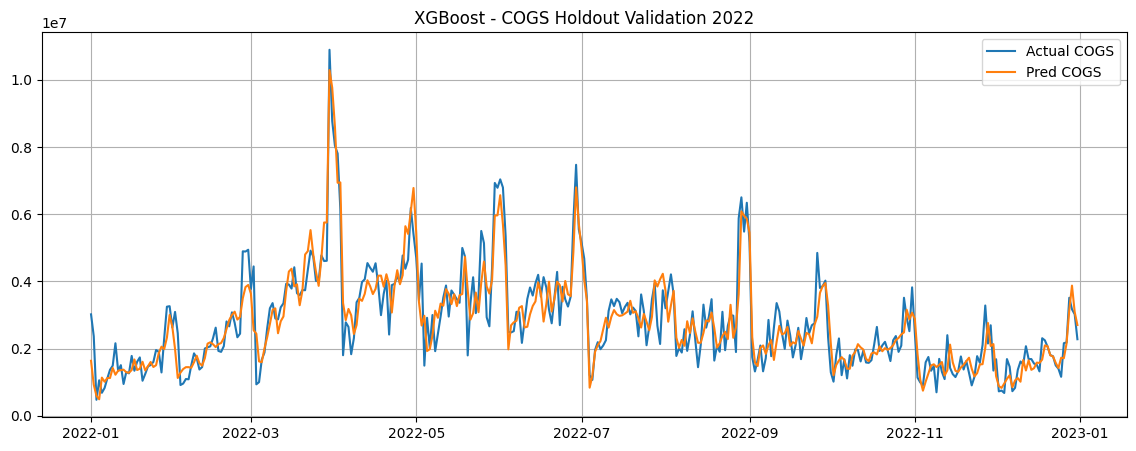


LightGBM - COGS HOLDOUT 2022
RMSE : 606,246.97
MAE  : 457,351.34
RMSPE: 27.75%
MAPE : 19.36%


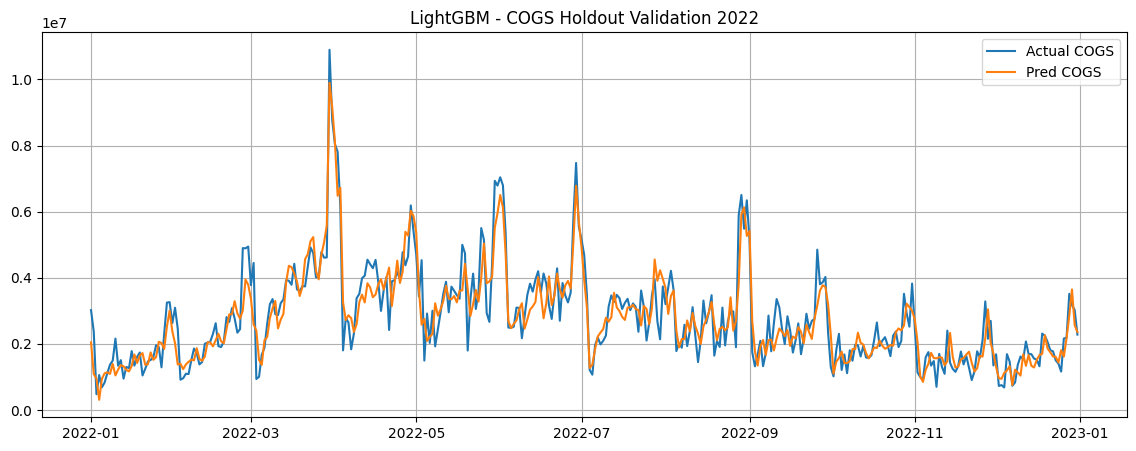


CatBoost - COGS HOLDOUT 2022
RMSE : 599,615.82
MAE  : 451,520.38
RMSPE: 27.04%
MAPE : 19.05%


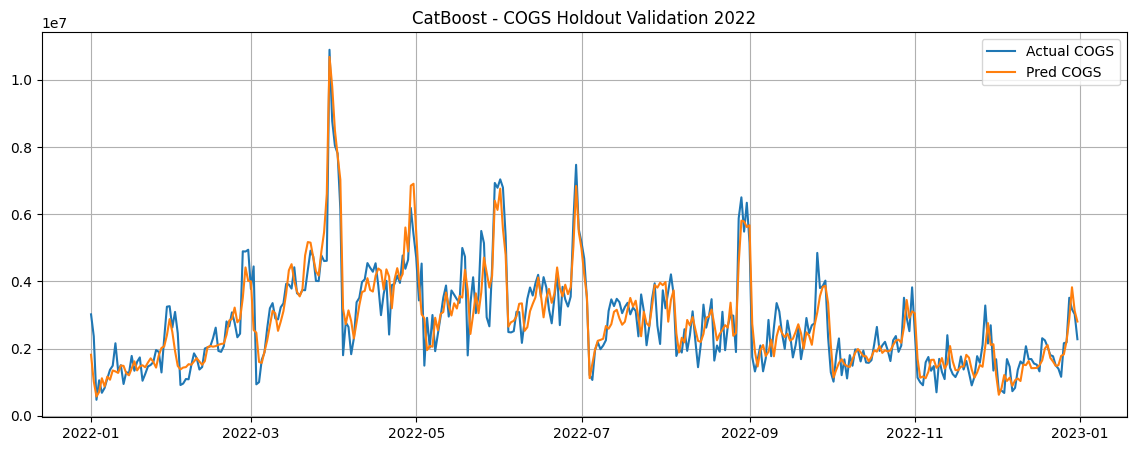

,model,target,RMSE,MAE,RMSPE,MAPE
0,CatBoost,COGS,599615.816852,451520.383802,27.035436,19.046099
1,LightGBM,COGS,606246.968159,457351.342432,27.749304,19.361874
2,XGBoost,COGS,610255.251238,454747.626640,26.822514,18.796675



BEST COGS MODEL
CatBoost
{'RMSE': np.float64(599615.8168515682), 'MAE': 451520.38380236423, 'RMSPE': np.float64(27.035435583520112), 'MAPE': np.float64(19.04609941064367)}


In [ ]:
# ============================================================
# BOX 10C — MODEL EVALUATION COGS
# ============================================================

def evaluate_cogs_model(model_name, model_class, best_params, fixed_params):
    """
    Đánh giá COGS trên holdout 2022.
    Sau đó lưu model, metric và feature importance.
    """

    daily_ml = make_cogs_features(df_cogs).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["COGS", "target"]
    ]

    split_date = "2022-01-01"

    train_df = daily_ml[daily_ml.index < split_date].copy()
    test_df = daily_ml[daily_ml.index >= split_date].copy()

    X_train = train_df[feature_cols]
    y_train = train_df["target"]

    X_test = test_df[feature_cols]
    y_test = test_df["target"]

    model = model_class(**fixed_params, **best_params)
    model.fit(X_train, y_train)

    test_pred = model.predict(X_test)
    test_pred = np.clip(test_pred, 0, None)

    metrics = evaluate_prediction(y_test, test_pred)

    print(f"\n{model_name} - COGS HOLDOUT 2022")
    print(f"RMSE : {metrics['RMSE']:,.2f}")
    print(f"MAE  : {metrics['MAE']:,.2f}")
    print(f"RMSPE: {metrics['RMSPE']:.2f}%")
    print(f"MAPE : {metrics['MAPE']:.2f}%")

    plt.figure(figsize=(14, 5))
    plt.plot(test_df.index, y_test, label="Actual COGS")
    plt.plot(test_df.index, test_pred, label="Pred COGS")
    plt.title(f"{model_name} - COGS Holdout Validation 2022")
    plt.legend()
    plt.show()

    fi = pd.DataFrame({
        "feature": feature_cols,
        "importance": model.feature_importances_
    }).sort_values("importance", ascending=False)

    return {
        "model_name": model_name,
        "target": "COGS",
        "model_class": model_class,
        "best_params": best_params,
        "fixed_params": fixed_params,
        "model": model,
        "metrics": metrics,
        "test_df": test_df,
        "test_pred": test_pred,
        "feature_cols": feature_cols,
        "fi": fi
    }


cogs_eval_results = []

cogs_eval_results.append(
    evaluate_cogs_model(
        "XGBoost",
        XGBRegressor,
        xgb_best_cogs,
        xgb_fixed_params_cogs
    )
)

cogs_eval_results.append(
    evaluate_cogs_model(
        "LightGBM",
        LGBMRegressor,
        lgbm_best_cogs,
        lgbm_fixed_params_cogs
    )
)

cogs_eval_results.append(
    evaluate_cogs_model(
        "CatBoost",
        CatBoostRegressor,
        cat_best_cogs,
        cat_fixed_params_cogs
    )
)

cogs_eval_summary = pd.DataFrame([
    {
        "model": r["model_name"],
        "target": r["target"],
        "RMSE": r["metrics"]["RMSE"],
        "MAE": r["metrics"]["MAE"],
        "RMSPE": r["metrics"]["RMSPE"],
        "MAPE": r["metrics"]["MAPE"]
    }
    for r in cogs_eval_results
]).sort_values("RMSE").reset_index(drop=True)

display(cogs_eval_summary)

# Chọn model COGS tốt nhất theo RMSE
best_cogs_result = cogs_eval_results[
    np.argmin([r["metrics"]["RMSE"] for r in cogs_eval_results])
]

print("\nBEST COGS MODEL")
print(best_cogs_result["model_name"])
print(best_cogs_result["metrics"])

###2.6. Model Integration


Top COGS features


,feature,importance
18,cogs_lag_1,33.284909
4,dayofmonth,13.107422
21,cogs_lag_7,4.707883
24,cogs_lag_28,4.003265
27,cogs_roll_min_7,3.907824
53,cogs_fourier_y_cos_3,2.968605
31,cogs_roll_min_14,2.846353
16,doy_sin,2.718024
42,cogs_diff_7,2.346970
22,cogs_lag_14,2.149521


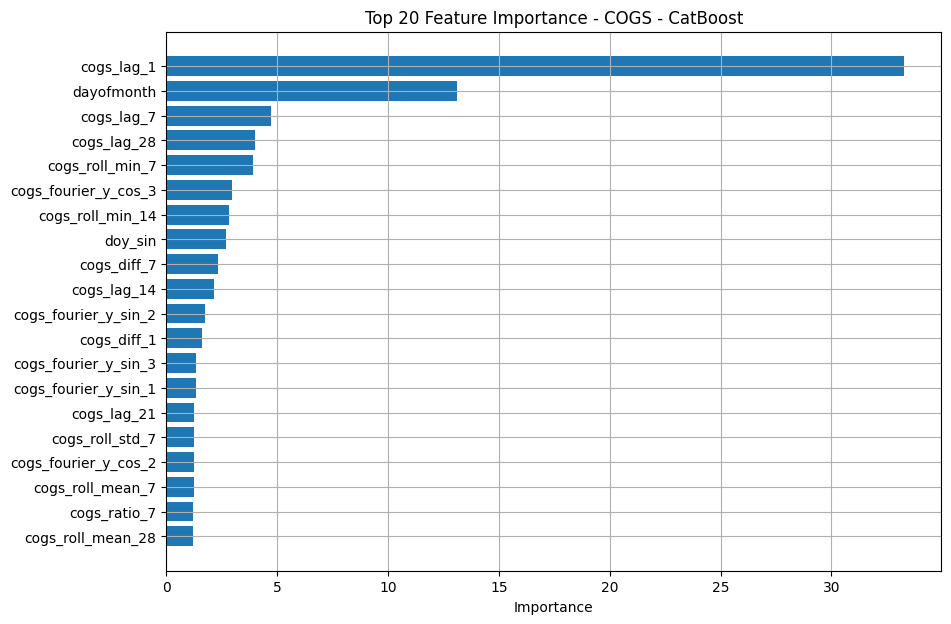

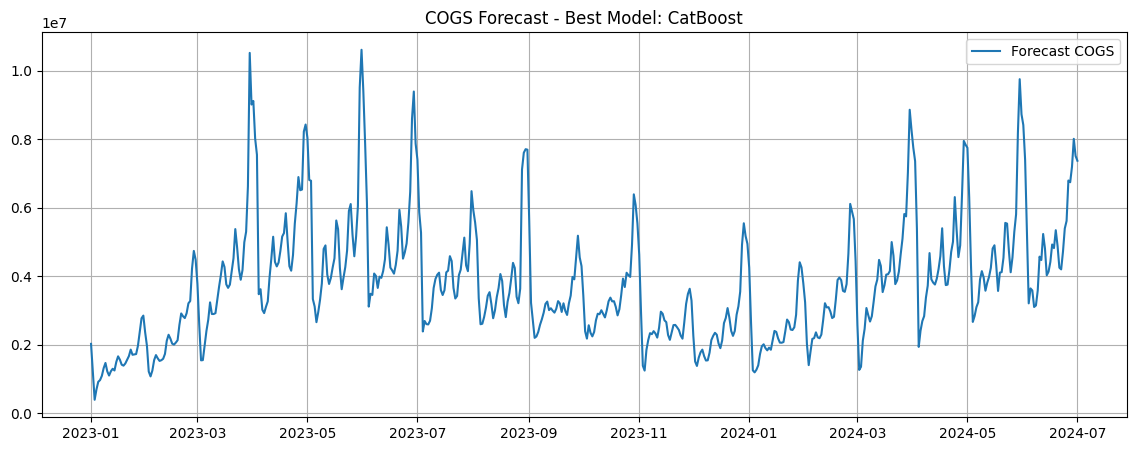

,Date,COGS
0,2023-01-01,2.030322e+06
1,2023-01-02,1.196563e+06
2,2023-01-03,3.990287e+05
3,2023-01-04,6.989406e+05
4,2023-01-05,9.229494e+05


,Date,COGS
543,2024-06-27,6.746189e+06
544,2024-06-28,7.198932e+06
545,2024-06-29,8.012140e+06
546,2024-06-30,7.511218e+06
547,2024-07-01,7.372630e+06



DONE - saved: submission_best_model_revenue_cogs.csv
Best Revenue model: XGBoost
Best COGS model: CatBoost


,Date,Revenue,COGS
0,2023-01-01,1.973441e+06,2.030322e+06
1,2023-01-02,1.634760e+06,1.196563e+06
2,2023-01-03,8.273451e+05,3.990287e+05
3,2023-01-04,9.422176e+05,6.989406e+05
4,2023-01-05,1.060890e+06,9.229494e+05


,Date,Revenue,COGS
543,2024-06-27,7504147.5,6.746189e+06
544,2024-06-28,6780410.5,7.198932e+06
545,2024-06-29,7856684.0,8.012140e+06
546,2024-06-30,7735415.5,7.511218e+06
547,2024-07-01,7636927.5,7.372630e+06


In [ ]:
# ============================================================
# BOX 11C — FEATURE IMPORTANCE, FORECAST COGS & SUBMISSION
# ============================================================

def plot_cogs_feature_importance(result, top_n=20):
    """
    Vẽ feature importance của model COGS tốt nhất.
    """

    fi = result["fi"].head(top_n).copy()
    fi = fi.sort_values("importance")

    plt.figure(figsize=(10, 7))
    plt.barh(fi["feature"], fi["importance"])
    plt.title(f"Top {top_n} Feature Importance - COGS - {result['model_name']}")
    plt.xlabel("Importance")
    plt.show()


def forecast_cogs_with_best_model(best_result):
    """
    Train lại COGS model tốt nhất trên toàn bộ dữ liệu 2012-2022.
    Sau đó forecast recursive cho giai đoạn 2023-01-01 đến 2024-07-01.
    """

    model_class = best_result["model_class"]
    fixed_params = best_result["fixed_params"]
    best_params = best_result["best_params"]

    daily_ml = make_cogs_features(df_cogs).dropna()

    feature_cols = [
        c for c in daily_ml.columns
        if c not in ["COGS", "target"]
    ]

    X_full = daily_ml[feature_cols]
    y_full = daily_ml["target"]

    final_model = model_class(**fixed_params, **best_params)
    final_model.fit(X_full, y_full)

    future_dates = pd.date_range(forecast_start, forecast_end, freq="D")
    history = df_cogs[["COGS"]].copy()

    preds = []

    for dt in future_dates:
        new_row = pd.DataFrame(index=[dt], data={"COGS": [np.nan]})
        temp = pd.concat([history, new_row])

        temp_feat = make_cogs_features(temp)
        pred = final_model.predict(temp_feat.loc[[dt], feature_cols])[0]
        pred = max(pred, 0)

        preds.append(pred)

        new_row["COGS"] = pred
        history = pd.concat([history, new_row])

    cogs_forecast = pd.DataFrame({
        "Date": future_dates,
        "COGS": preds
    })

    plt.figure(figsize=(14, 5))
    plt.plot(cogs_forecast["Date"], cogs_forecast["COGS"], label="Forecast COGS")
    plt.title(f"COGS Forecast - Best Model: {best_result['model_name']}")
    plt.legend()
    plt.show()

    return cogs_forecast, final_model


print("\nTop COGS features")
display(best_cogs_result["fi"].head(20))

plot_cogs_feature_importance(best_cogs_result, top_n=20)

cogs_forecast, final_cogs_model = forecast_cogs_with_best_model(best_cogs_result)

display(cogs_forecast.head())
display(cogs_forecast.tail())


# ============================================================
# TẠO SUBMISSION CUỐI CÙNG
# ============================================================

submission = pd.merge(
    revenue_forecast,
    cogs_forecast,
    on="Date",
    how="inner"
)

submission = submission[submission["Date"] <= submission_end].copy()

submission["Date"] = pd.to_datetime(submission["Date"]).dt.strftime("%Y-%m-%d")

submission = submission[["Date", "Revenue", "COGS"]]

submission.to_csv("submission_best_model_revenue_cogs.csv", index=False)

print("\nDONE - saved: submission_best_model_revenue_cogs.csv")
print("Best Revenue model:", best_revenue_result["model_name"])
print("Best COGS model:", best_cogs_result["model_name"])

display(submission.head())
display(submission.tail())

Using existing final_cogs_model.
X_cogs shape: (3777, 54)
y_cogs shape: (3777,)

Top 20 Feature Importance - COGS


,feature,importance
18,cogs_lag_1,32.986811
4,dayofmonth,13.945164
21,cogs_lag_7,5.086236
24,cogs_lag_28,3.779319
16,doy_sin,3.606820
27,cogs_roll_min_7,3.318315
31,cogs_roll_min_14,3.129370
53,cogs_fourier_y_cos_3,2.941810
42,cogs_diff_7,2.395697
22,cogs_lag_14,2.395670


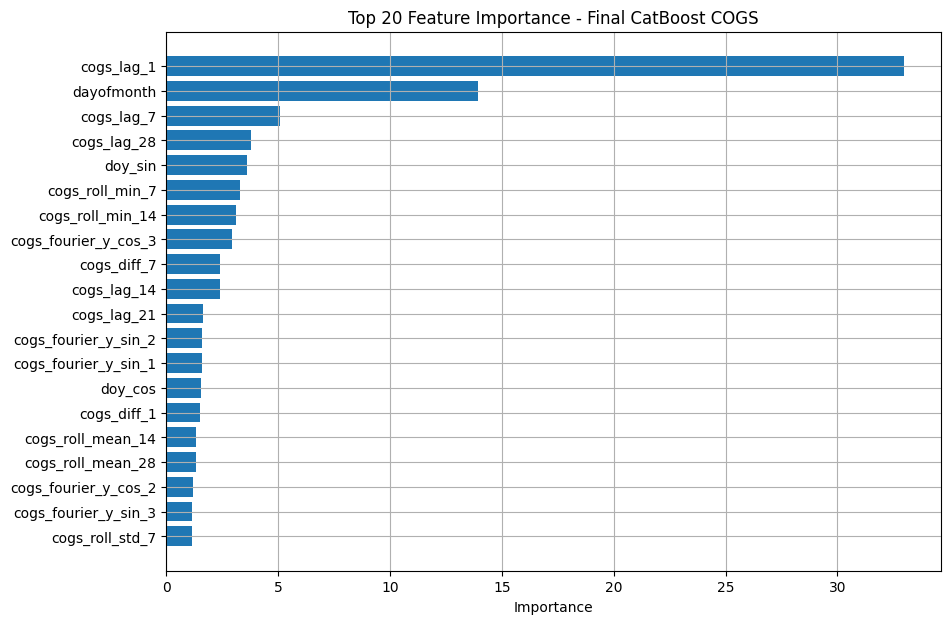

X_cogs_sample shape: (1000, 54)
DONE - COGS SHAP values calculated.


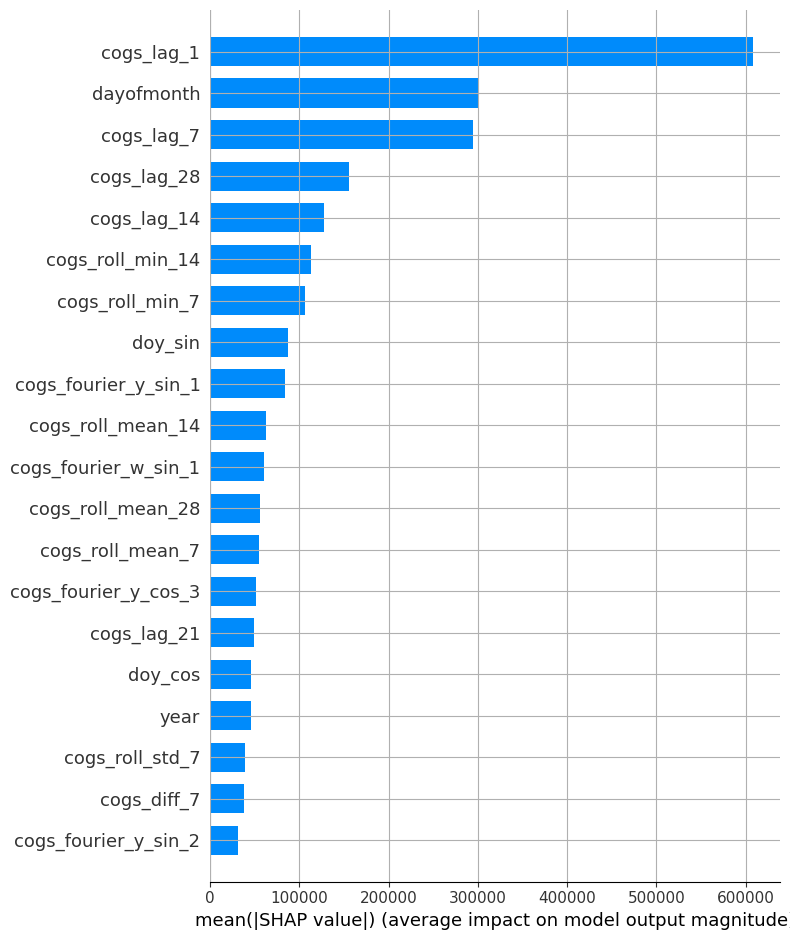

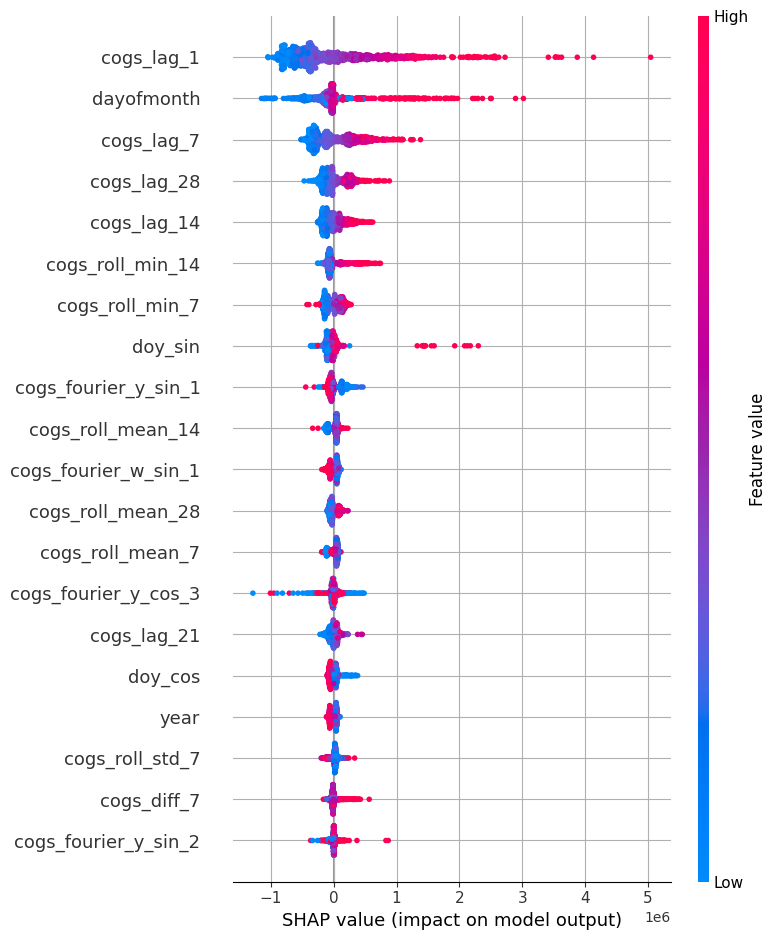


Top 20 SHAP Importance - COGS


,feature,mean_abs_shap
18,cogs_lag_1,608034.460192
4,dayofmonth,299645.640645
21,cogs_lag_7,294554.078026
24,cogs_lag_28,155240.148246
22,cogs_lag_14,127133.644878
31,cogs_roll_min_14,112547.344645
27,cogs_roll_min_7,105786.565505
16,doy_sin,87526.813018
48,cogs_fourier_y_sin_1,84225.839534
29,cogs_roll_mean_14,62677.299014


In [ ]:
# ============================================================
# COGS SHAP — USE EXISTING BEST MODEL
# Dùng khi notebook đã có best_cogs_result hoặc final_cogs_model
# ============================================================

# Nếu chưa cài shap thì bỏ comment:
# !pip install shap -q

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1) Lấy lại final COGS model
# ------------------------------------------------------------

# Nếu đã có final_cogs_model thì dùng luôn
try:
    final_cogs_model
    print("Using existing final_cogs_model.")
except NameError:
    # Nếu chưa có final_cogs_model nhưng có best_cogs_result
    final_cogs_model = best_cogs_result["model"]
    print("Using best_cogs_result['model'].")

# ------------------------------------------------------------
# 2) Tạo lại feature COGS
# ------------------------------------------------------------

cogs_ml = make_cogs_features(df_cogs).dropna()

cogs_feature_cols = [
    c for c in cogs_ml.columns
    if c not in ["COGS", "target"]
]

X_cogs = cogs_ml[cogs_feature_cols]
y_cogs = cogs_ml["target"]

print("X_cogs shape:", X_cogs.shape)
print("y_cogs shape:", y_cogs.shape)

# ------------------------------------------------------------
# 3) Feature importance
# ------------------------------------------------------------

cogs_fi = pd.DataFrame({
    "feature": cogs_feature_cols,
    "importance": final_cogs_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop 20 Feature Importance - COGS")
display(cogs_fi.head(20))

top_cogs_fi = cogs_fi.head(20).sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(top_cogs_fi["feature"], top_cogs_fi["importance"])
plt.title("Top 20 Feature Importance - Final CatBoost COGS")
plt.xlabel("Importance")
plt.grid(True, axis="x")
plt.show()

# ------------------------------------------------------------
# 4) SHAP sample
# ------------------------------------------------------------

X_cogs_sample = X_cogs.sample(
    n=min(1000, len(X_cogs)),
    random_state=42
)

print("X_cogs_sample shape:", X_cogs_sample.shape)

# ------------------------------------------------------------
# 5) Tính SHAP values
# ------------------------------------------------------------

cogs_explainer = shap.TreeExplainer(final_cogs_model)
cogs_shap_values = cogs_explainer.shap_values(X_cogs_sample)

print("DONE - COGS SHAP values calculated.")

# ------------------------------------------------------------
# 6) SHAP bar plot
# ------------------------------------------------------------

shap.summary_plot(
    cogs_shap_values,
    X_cogs_sample,
    plot_type="bar",
    max_display=20,
    show=True
)

# ------------------------------------------------------------
# 7) SHAP beeswarm plot
# ------------------------------------------------------------

shap.summary_plot(
    cogs_shap_values,
    X_cogs_sample,
    plot_type="dot",
    max_display=20,
    show=True
)

# ------------------------------------------------------------
# 8) SHAP importance table
# ------------------------------------------------------------

cogs_shap_importance = pd.DataFrame({
    "feature": X_cogs_sample.columns,
    "mean_abs_shap": np.abs(cogs_shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print("\nTop 20 SHAP Importance - COGS")
display(cogs_shap_importance.head(20))

###2.7. Submission

In [ ]:
# ============================================================
# TẠO SUBMISSION CUỐI CÙNG VÀ TẢI VỀ MÁY
# ============================================================

from google.colab import files
import pandas as pd

submission = pd.merge(
    revenue_forecast,
    cogs_forecast,
    on="Date",
    how="inner"
)

submission = submission[submission["Date"] <= submission_end].copy()

submission["Date"] = pd.to_datetime(submission["Date"]).dt.strftime("%Y-%m-%d")

submission = submission[["Date", "Revenue", "COGS"]]

file_name = "submission_best_model_revenue_cogs.csv"

submission.to_csv(file_name, index=False)

print("\nDONE - saved locally in Colab and downloading:")
print(file_name)

print("Best Revenue model:", best_revenue_result["model_name"])
print("Best COGS model:", best_cogs_result["model_name"])

display(submission.head())
display(submission.tail())

files.download(file_name)


DONE - saved locally in Colab and downloading:
submission_best_model_revenue_cogs.csv
Best Revenue model: XGBoost
Best COGS model: CatBoost


,Date,Revenue,COGS
0,2023-01-01,1.973441e+06,2.030322e+06
1,2023-01-02,1.634760e+06,1.196563e+06
2,2023-01-03,8.273451e+05,3.990287e+05
3,2023-01-04,9.422176e+05,6.989406e+05
4,2023-01-05,1.060890e+06,9.229494e+05


,Date,Revenue,COGS
543,2024-06-27,7504147.5,6.746189e+06
544,2024-06-28,6780410.5,7.198932e+06
545,2024-06-29,7856684.0,8.012140e+06
546,2024-06-30,7735415.5,7.511218e+06
547,2024-07-01,7636927.5,7.372630e+06


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>